
# Projet RH — Modélisation complète sans data leakage

## Objectif métier

L'objectif est de prédire les employés susceptibles de quitter l'entreprise.

La cible est :

- `0` : l'employé ne quitte pas l'entreprise ;
- `1` : l'employé quitte l'entreprise.

## Contenu du notebook

Ce notebook reprend l'ensemble des étapes réalisées :

1. chargement des fichiers sources ;
2. construction du DataFrame central ;
3. statistiques descriptives rapides ;
4. création de la cible `y` ;
5. feature engineering ligne par ligne ;
6. création de `X_brut` ;
7. liste modifiable des features ;
8. split 80 % train / 20 % test caché ;
9. preprocessing sans data leakage avec `Pipeline` et `ColumnTransformer` ;
10. distinction entre features numériques et features catégorielles encodées en one-hot ;
11. entraînement de trois modèles :
   - DummyClassifier ;
   - LogisticRegression ;
   - RandomForestClassifier ;
12. évaluation train/test caché ;
13. visualisation des matrices de confusion ;
14. visualisation des métriques ;
15. cross-validation sur les 80 % du train ;
16. F5-score pour privilégier le recall ;
17. GridSearchCV sur la régression logistique ;
18. évaluation finale de la régression logistique optimisée sur le jeu caché de 20 %.

## Point méthodologique important

Le jeu de test caché de 20 % n'est jamais utilisé pour apprendre :

- l'imputation ;
- l'encodage one-hot ;
- la suppression des colonnes constantes ;
- les hyperparamètres ;
- la sélection du meilleur modèle.

Il sert uniquement à l'évaluation finale.


## 1. Imports

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    make_scorer,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)


## 2. Chargement des fichiers sources

In [ ]:

# Adapter les chemins si nécessaire dans VS Code.
chemin_sirh = "extrait_sirh.csv"
chemin_eval = "extrait_eval.csv"
chemin_sondage = "extrait_sondage.csv"

try:
    df_sirh = pd.read_csv(chemin_sirh)
    df_eval = pd.read_csv(chemin_eval)
    df_sondage = pd.read_csv(chemin_sondage)
except FileNotFoundError:
    # Chemins utilisés dans l'environnement ChatGPT.
    df_sirh = pd.read_csv("extrait_sirh.csv")
    df_eval = pd.read_csv("extrait_eval.csv")
    df_sondage = pd.read_csv("extrait_sondage.csv")

print("SIRH :", df_sirh.shape)
print("Évaluation :", df_eval.shape)
print("Sondage :", df_sondage.shape)


SIRH : (1470, 12)
Évaluation : (1470, 10)
Sondage : (1470, 12)


## 3. Aperçu des fichiers sources

In [3]:

print("Colonnes SIRH")
display(pd.DataFrame({"colonne": df_sirh.columns}))

print("Colonnes Évaluation")
display(pd.DataFrame({"colonne": df_eval.columns}))

print("Colonnes Sondage")
display(pd.DataFrame({"colonne": df_sondage.columns}))

display(df_sirh.head())
display(df_eval.head())
display(df_sondage.head())


Colonnes SIRH


,colonne
0,id_employee
1,age
2,genre
3,revenu_mensuel
4,statut_marital
5,departement
6,poste
7,nombre_experiences_precedentes
8,nombre_heures_travailless
9,annee_experience_totale


Colonnes Évaluation


,colonne
0,satisfaction_employee_environnement
1,note_evaluation_precedente
2,niveau_hierarchique_poste
3,satisfaction_employee_nature_travail
4,satisfaction_employee_equipe
5,satisfaction_employee_equilibre_pro_perso
6,eval_number
7,note_evaluation_actuelle
8,heure_supplementaires
9,augementation_salaire_precedente


Colonnes Sondage


,colonne
0,a_quitte_l_entreprise
1,nombre_participation_pee
2,nb_formations_suivies
3,nombre_employee_sous_responsabilite
4,code_sondage
5,distance_domicile_travail
6,niveau_education
7,domaine_etude
8,ayant_enfants
9,frequence_deplacement


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


## 4. Construction du DataFrame central

In [4]:

def construire_dataframe_central(df_sirh, df_eval, df_sondage):
    """
    Construit le DataFrame central à partir des trois fichiers sources.

    Jointures :
    - SIRH : clé `id_employee`
    - Évaluation : extraction de l'identifiant depuis `eval_number`, ex. E_1 -> 1
    - Sondage : renommage de `code_sondage` en `id_employee`
    """

    df_sirh = df_sirh.copy()
    df_eval = df_eval.copy()
    df_sondage = df_sondage.copy()

    df_eval["id_employee"] = (
        df_eval["eval_number"]
        .astype(str)
        .str.extract(r"(\d+)")
        .astype(int)
    )

    df_sondage = df_sondage.rename(columns={"code_sondage": "id_employee"})

    df_central = (
        df_sirh
        .merge(df_eval, on="id_employee", how="inner", validate="one_to_one")
        .merge(df_sondage, on="id_employee", how="inner", validate="one_to_one")
    )

    return df_central


df_central = construire_dataframe_central(df_sirh, df_eval, df_sondage)

print("DataFrame central :", df_central.shape)
display(df_central.head())


DataFrame central : (1470, 33)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,E_1,3,Oui,11 %,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,E_2,4,Non,23 %,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,E_4,3,Oui,15 %,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,E_5,3,Oui,11 %,Non,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,E_7,3,Non,12 %,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2


## 5. Statistiques descriptives rapides

In [5]:

print("Dimensions du DataFrame central :", df_central.shape)

print("\nValeurs manquantes par colonne :")
display(
    df_central
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .rename("taux_valeurs_manquantes_pct")
    .to_frame()
    .query("taux_valeurs_manquantes_pct > 0")
)

print("\nDescription des variables numériques :")
display(df_central.describe().T)

print("\nDistribution de la cible brute :")
display(df_central["a_quitte_l_entreprise"].value_counts(dropna=False).to_frame("effectif"))
display((df_central["a_quitte_l_entreprise"].value_counts(normalize=True) * 100).round(2).to_frame("pourcentage"))


Dimensions du DataFrame central : (1470, 33)

Valeurs manquantes par colonne :


,taux_valeurs_manquantes_pct



Description des variables numériques :


,count,mean,std,min,25%,50%,75%,max
id_employee,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
revenu_mensuel,1470.0,6502.931293,4707.956783,1009.0,2911.00,4919.0,8379.00,19999.0
nombre_experiences_precedentes,1470.0,2.693197,2.498009,0.0,1.00,2.0,4.00,9.0
nombre_heures_travailless,1470.0,80.000000,0.000000,80.0,80.00,80.0,80.00,80.0
annee_experience_totale,1470.0,11.279592,7.780782,0.0,6.00,10.0,15.00,40.0
annees_dans_l_entreprise,1470.0,7.008163,6.126525,0.0,3.00,5.0,9.00,40.0
annees_dans_le_poste_actuel,1470.0,4.229252,3.623137,0.0,2.00,3.0,7.00,18.0
satisfaction_employee_environnement,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
note_evaluation_precedente,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0



Distribution de la cible brute :


,effectif
a_quitte_l_entreprise,
Non,1233
Oui,237


,pourcentage
a_quitte_l_entreprise,
Non,83.88
Oui,16.12


## 6. Colonnes constantes du DataFrame central

In [6]:

colonnes_constantes_central = [
    col for col in df_central.columns
    if df_central[col].nunique(dropna=False) <= 1
]

print("Colonnes constantes dans le dataset central :")
print(colonnes_constantes_central)

for col in colonnes_constantes_central:
    print(f"{col} -> valeur unique : {df_central[col].iloc[0]}")


Colonnes constantes dans le dataset central :
['nombre_heures_travailless', 'nombre_employee_sous_responsabilite', 'ayant_enfants']
nombre_heures_travailless -> valeur unique : 80
nombre_employee_sous_responsabilite -> valeur unique : 1
ayant_enfants -> valeur unique : Y



## 7. Création de la cible `y`

La variable cible est `a_quitte_l_entreprise`.

On l'encode ainsi :

- `Non` -> `0`
- `Oui` -> `1`

La classe `1` est la classe positive : employés qui quittent l'entreprise.


In [7]:

df = df_central.copy()

y = df["a_quitte_l_entreprise"].map({
    "Non": 0,
    "Oui": 1
})

if y.isna().any():
    raise ValueError("La cible contient des valeurs non reconnues.")

print("Distribution de y :")
display(y.value_counts().rename("effectif").to_frame())

print("Distribution de y en pourcentage :")
display((y.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())


Distribution de y :


,effectif
a_quitte_l_entreprise,
0,1233
1,237


Distribution de y en pourcentage :


,pourcentage
a_quitte_l_entreprise,
0,83.88
1,16.12



## 8. Feature engineering ligne par ligne

Ces transformations ne créent pas de data leakage car elles utilisent uniquement les informations de la ligne courante.

À l'inverse, les transformations qui apprennent des statistiques globales, comme l'imputation ou l'encodage one-hot, seront faites dans un pipeline sklearn après le split train/test.


In [8]:

def ajouter_features_metier(df):
    """
    Ajoute des variables métier calculées ligne par ligne.
    """

    df = df.copy()
    eps = np.finfo(float).eps

    df["augmentation_salaire_precedente_pct"] = (
        df["augementation_salaire_precedente"]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.strip()
        .astype(float)
    )

    df["ratio_anciennete_experience"] = (
        df["annees_dans_l_entreprise"] / (df["annee_experience_totale"] + eps)
    )

    df["ratio_temps_poste_anciennete"] = (
        df["annees_dans_le_poste_actuel"] / (df["annees_dans_l_entreprise"] + eps)
    )

    df["ratio_promotion_anciennete"] = (
        df["annees_depuis_la_derniere_promotion"] / (df["annees_dans_l_entreprise"] + eps)
    )

    df["revenu_par_annee_experience"] = (
        df["revenu_mensuel"] / (df["annee_experience_totale"] + eps)
    )

    return df


df = ajouter_features_metier(df)

features_creees = [
    "augmentation_salaire_precedente_pct",
    "ratio_anciennete_experience",
    "ratio_temps_poste_anciennete",
    "ratio_promotion_anciennete",
    "revenu_par_annee_experience"
]

display(df[features_creees].head())


,augmentation_salaire_precedente_pct,ratio_anciennete_experience,ratio_temps_poste_anciennete,ratio_promotion_anciennete,revenu_par_annee_experience
0,11.0,0.750000,0.666667,0.000,749.125000
1,23.0,1.000000,0.700000,0.100,513.000000
2,15.0,0.000000,0.000000,0.000,298.571429
3,11.0,1.000000,0.875000,0.375,363.625000
4,12.0,0.333333,1.000000,1.000,578.000000



## 9. Création de `X_brut`

`X_brut` contient les variables explicatives avant preprocessing.

On supprime :

- la cible ;
- les identifiants techniques ;
- la version texte brute de l'augmentation de salaire, remplacée par sa version numérique.


In [9]:

colonnes_a_supprimer = [
    "a_quitte_l_entreprise",
    "id_employee",
    "eval_number",
    "augementation_salaire_precedente"
]

X_brut = df.drop(columns=colonnes_a_supprimer, errors="ignore")

print("Dimensions X_brut :", X_brut.shape)
print("Dimensions y :", y.shape)

display(X_brut.head())


Dimensions X_brut : (1470, 34)
Dimensions y : (1470,)


,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,augmentation_salaire_precedente_pct,ratio_anciennete_experience,ratio_temps_poste_anciennete,ratio_promotion_anciennete,revenu_par_annee_experience
0,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,3,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5,11.0,0.750000,0.666667,0.000,749.125000
1,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,4,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7,23.0,1.000000,0.700000,0.100,513.000000
2,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,3,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0,15.0,0.000000,0.000000,0.000,298.571429
3,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,3,Oui,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0,11.0,1.000000,0.875000,0.375,363.625000
4,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,3,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2,12.0,0.333333,1.000000,1.000,578.000000



## 10. Liste modifiable des features brutes

Pour retirer une variable du modèle, l'ajouter dans `features_a_retirer`.

Cette étape ne crée pas de fuite de données : elle ne dépend pas des scores du modèle ni de statistiques apprises sur le jeu de test.


In [10]:

features_a_utiliser = [
    "age",
    "genre",
    "revenu_mensuel",
    "statut_marital",
    "departement",
    "poste",
    "nombre_experiences_precedentes",
    "nombre_heures_travailless",
    "annee_experience_totale",
    "annees_dans_l_entreprise",
    "annees_dans_le_poste_actuel",
    "satisfaction_employee_environnement",
    "note_evaluation_precedente",
    "niveau_hierarchique_poste",
    "satisfaction_employee_nature_travail",
    "satisfaction_employee_equipe",
    "satisfaction_employee_equilibre_pro_perso",
    "note_evaluation_actuelle",
    "heure_supplementaires",
    "nombre_participation_pee",
    "nb_formations_suivies",
    "nombre_employee_sous_responsabilite",
    "distance_domicile_travail",
    "niveau_education",
    "domaine_etude",
    "ayant_enfants",
    "frequence_deplacement",
    "annees_depuis_la_derniere_promotion",
    "annes_sous_responsable_actuel",
    "augmentation_salaire_precedente_pct",
    "ratio_anciennete_experience",
    "ratio_temps_poste_anciennete",
    "ratio_promotion_anciennete",
    "revenu_par_annee_experience",
]

# Ajouter ici les variables à retirer si besoin.
features_a_retirer = [
    # "genre",
    # "revenu_mensuel",
    # "nombre_heures_travailless",
]

features_a_utiliser = [
    feature for feature in features_a_utiliser
    if feature not in features_a_retirer
]

features_absentes = [
    feature for feature in features_a_utiliser
    if feature not in X_brut.columns
]

if features_absentes:
    raise ValueError(f"Features absentes de X_brut : {features_absentes}")

X_brut = X_brut[features_a_utiliser].copy()

print("Nombre de features brutes utilisées avant encodage :", len(features_a_utiliser))
display(pd.DataFrame({
    "numero": range(1, len(features_a_utiliser) + 1),
    "feature_brute": features_a_utiliser
}))


Nombre de features brutes utilisées avant encodage : 34


,numero,feature_brute
0,1,age
1,2,genre
2,3,revenu_mensuel
3,4,statut_marital
4,5,departement
5,6,poste
6,7,nombre_experiences_precedentes
7,8,nombre_heures_travailless
8,9,annee_experience_totale
9,10,annees_dans_l_entreprise



## 11. Split 80 % train / 20 % jeu caché

La séparation est faite avant toute imputation, tout encodage et toute suppression de colonnes constantes.

- `X_train_brut`, `y_train` : utilisés pour apprendre les transformations, entraîner les modèles, faire la cross-validation et GridSearchCV ;
- `X_test_cache`, `y_test_cache` : jeu caché de 20 %, utilisé uniquement pour l'évaluation finale.

La stratification se fait sur `y` afin de conserver la proportion d'employés qui quittent dans le train et le test.


In [11]:

X_train_brut, X_test_cache, y_train, y_test_cache = train_test_split(
    X_brut,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train_brut :", X_train_brut.shape)
print("X_test_cache :", X_test_cache.shape)
print("y_train :", y_train.shape)
print("y_test_cache :", y_test_cache.shape)

print("\nDistribution cible - complet :")
display((y.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())

print("\nDistribution cible - train :")
display((y_train.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())

print("\nDistribution cible - test caché :")
display((y_test_cache.value_counts(normalize=True) * 100).round(2).rename("pourcentage").to_frame())


X_train_brut : (1176, 34)
X_test_cache : (294, 34)
y_train : (1176,)
y_test_cache : (294,)

Distribution cible - complet :


,pourcentage
a_quitte_l_entreprise,
0,83.88
1,16.12



Distribution cible - train :


,pourcentage
a_quitte_l_entreprise,
0,83.84
1,16.16



Distribution cible - test caché :


,pourcentage
a_quitte_l_entreprise,
0,84.01
1,15.99


## 12. Identification des colonnes numériques et catégorielles sur le train uniquement

In [12]:

colonnes_numeriques = X_train_brut.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

colonnes_categorielles = X_train_brut.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Nombre de colonnes numériques :", len(colonnes_numeriques))
print(colonnes_numeriques)

print("\nNombre de colonnes catégorielles :", len(colonnes_categorielles))
print(colonnes_categorielles)


Nombre de colonnes numériques : 26
['age', 'revenu_mensuel', 'nombre_experiences_precedentes', 'nombre_heures_travailless', 'annee_experience_totale', 'annees_dans_l_entreprise', 'annees_dans_le_poste_actuel', 'satisfaction_employee_environnement', 'note_evaluation_precedente', 'niveau_hierarchique_poste', 'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe', 'satisfaction_employee_equilibre_pro_perso', 'note_evaluation_actuelle', 'nombre_participation_pee', 'nb_formations_suivies', 'nombre_employee_sous_responsabilite', 'distance_domicile_travail', 'niveau_education', 'annees_depuis_la_derniere_promotion', 'annes_sous_responsable_actuel', 'augmentation_salaire_precedente_pct', 'ratio_anciennete_experience', 'ratio_temps_poste_anciennete', 'ratio_promotion_anciennete', 'revenu_par_annee_experience']

Nombre de colonnes catégorielles : 8
['genre', 'statut_marital', 'departement', 'poste', 'heure_supplementaires', 'domaine_etude', 'ayant_enfants', 'frequence_deplacement

C:\Users\johnd\AppData\Local\Temp\ipykernel_31080\1928941944.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colonnes_categorielles = X_train_brut.select_dtypes(



## 13. Préprocessing sans data leakage

Le preprocessing est intégré dans un `Pipeline`.

Lors du `fit`, les étapes suivantes sont apprises uniquement sur le train :

- imputation médiane des variables numériques ;
- imputation par modalité fréquente des variables catégorielles ;
- encodage OneHotEncoder ;
- suppression des colonnes constantes avec VarianceThreshold.

Le jeu caché de test est seulement transformé avec les règles apprises sur le train.


In [13]:

def creer_one_hot_encoder():
    """
    Crée un OneHotEncoder compatible avec différentes versions de sklearn.
    """
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse=False
        )


preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerique",
            SimpleImputer(strategy="median"),
            colonnes_numeriques
        ),
        (
            "categoriel",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", creer_one_hot_encoder())
            ]),
            colonnes_categorielles
        )
    ],
    remainder="drop"
)

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerique', ...), ('categoriel', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n


## 14. Définition des trois modèles

Les trois modèles attendus sont :

- un modèle étalon : `DummyClassifier` ;
- un modèle linéaire : `LogisticRegression` ;
- un modèle non-linéaire à base d'arbres : `RandomForestClassifier`.

La Random Forest est ici définie sans `class_weight="balanced"` afin de comparer un modèle d'arbre plus prudent.  
La régression logistique conserve `class_weight="balanced"` car la classe positive est minoritaire.


In [14]:

modeles = {
    "DummyClassifier": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("variance_threshold", VarianceThreshold(threshold=0.0)),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),

    "LogisticRegression": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("variance_threshold", VarianceThreshold(threshold=0.0)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "RandomForestClassifier": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("variance_threshold", VarianceThreshold(threshold=0.0)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

modeles


{'DummyClassifier': Pipeline(steps=[('preprocessing',
                  ColumnTransformer(transformers=[('numerique',
                                                   SimpleImputer(strategy='median'),
                                                   ['age', 'revenu_mensuel',
                                                    'nombre_experiences_precedentes',
                                                    'nombre_heures_travailless',
                                                    'annee_experience_totale',
                                                    'annees_dans_l_entreprise',
                                                    'annees_dans_le_poste_actuel',
                                                    'satisfaction_employee_environnement',
                                                    'note_evaluation_precedente',
                                                    'niv...
                                                                    SimpleImpu

## 15. Entraînement simple des trois modèles sur les 80 % du train

In [15]:

modeles_entraines = {}

for nom_modele, pipeline in modeles.items():
    pipeline.fit(X_train_brut, y_train)
    modeles_entraines[nom_modele] = pipeline
    print(f"{nom_modele} entraîné sur le jeu d'apprentissage.")


DummyClassifier entraîné sur le jeu d'apprentissage.


LogisticRegression entraîné sur le jeu d'apprentissage.
RandomForestClassifier entraîné sur le jeu d'apprentissage.



## 16. Liste détaillée des features après preprocessing

Cette section distingue explicitement :

- les features numériques ;
- les features catégorielles encodées avec OneHotEncoder ;
- les features supprimées par VarianceThreshold ;
- les features finales réellement envoyées au modèle.


In [16]:

def recuperer_features_detaillees_pipeline(pipeline, colonnes_numeriques, colonnes_categorielles):
    """
    Récupère la liste détaillée des features après preprocessing.
    """

    preprocessor_fitted = pipeline.named_steps["preprocessing"]
    variance_fitted = pipeline.named_steps["variance_threshold"]

    noms_features_preprocessing = preprocessor_fitted.get_feature_names_out()
    masque_variance = variance_fitted.get_support()

    df_features_preprocessing = pd.DataFrame({
        "feature_apres_preprocessing": noms_features_preprocessing,
        "conservee_apres_variance_threshold": masque_variance
    })

    lignes = []

    for col in colonnes_numeriques:
        lignes.append({
            "type_feature": "numérique",
            "variable_originale": col,
            "modalite_one_hot": np.nan,
            "feature_apres_preprocessing": f"numerique__{col}",
            "encodage": "imputation médiane",
        })

    pipeline_categoriel = preprocessor_fitted.named_transformers_["categoriel"]
    onehot_encoder = pipeline_categoriel.named_steps["onehot"]

    noms_features_onehot = onehot_encoder.get_feature_names_out(colonnes_categorielles)

    for nom_feature_onehot in noms_features_onehot:
        variable_originale = None
        modalite = None

        for col in colonnes_categorielles:
            prefixe = f"{col}_"
            if nom_feature_onehot.startswith(prefixe):
                variable_originale = col
                modalite = nom_feature_onehot[len(prefixe):]
                break

        lignes.append({
            "type_feature": "catégorielle encodée one-hot",
            "variable_originale": variable_originale,
            "modalite_one_hot": modalite,
            "feature_apres_preprocessing": f"categoriel__{nom_feature_onehot}",
            "encodage": "OneHotEncoder drop='first'",
        })

    df_features_detaillees = pd.DataFrame(lignes)

    df_features_detaillees = df_features_detaillees.merge(
        df_features_preprocessing,
        on="feature_apres_preprocessing",
        how="left"
    )

    df_features_detaillees.insert(
        0,
        "numero",
        range(1, len(df_features_detaillees) + 1)
    )

    return df_features_detaillees


df_features_detaillees = recuperer_features_detaillees_pipeline(
    pipeline=modeles_entraines["RandomForestClassifier"],
    colonnes_numeriques=colonnes_numeriques,
    colonnes_categorielles=colonnes_categorielles
)

print("Nombre total de features après preprocessing avant suppression des constantes :")
print(len(df_features_detaillees))

print("\nRépartition par type :")
display(df_features_detaillees["type_feature"].value_counts().to_frame("nombre_features"))

print("\nFeatures détaillées :")
display(df_features_detaillees)

df_features_finales_conservees = (
    df_features_detaillees
    .loc[df_features_detaillees["conservee_apres_variance_threshold"]]
    .copy()
    .reset_index(drop=True)
)

df_features_finales_conservees["numero"] = range(1, len(df_features_finales_conservees) + 1)

print("\nNombre de features finales réellement envoyées au modèle :")
print(len(df_features_finales_conservees))

display(df_features_finales_conservees)


Nombre total de features après preprocessing avant suppression des constantes :
47

Répartition par type :


,nombre_features
type_feature,
numérique,26
catégorielle encodée one-hot,21



Features détaillées :


,numero,type_feature,variable_originale,modalite_one_hot,feature_apres_preprocessing,encodage,conservee_apres_variance_threshold
0,1,numérique,age,NaN,numerique__age,imputation médiane,True
1,2,numérique,revenu_mensuel,NaN,numerique__revenu_mensuel,imputation médiane,True
2,3,numérique,nombre_experiences_precedentes,NaN,numerique__nombre_experiences_precedentes,imputation médiane,True
3,4,numérique,nombre_heures_travailless,NaN,numerique__nombre_heures_travailless,imputation médiane,False
4,5,numérique,annee_experience_totale,NaN,numerique__annee_experience_totale,imputation médiane,True
5,6,numérique,annees_dans_l_entreprise,NaN,numerique__annees_dans_l_entreprise,imputation médiane,True
6,7,numérique,annees_dans_le_poste_actuel,NaN,numerique__annees_dans_le_poste_actuel,imputation médiane,True
7,8,numérique,satisfaction_employee_environnement,NaN,numerique__satisfaction_employee_environnement,imputation médiane,True
8,9,numérique,note_evaluation_precedente,NaN,numerique__note_evaluation_precedente,imputation médiane,True
9,10,numérique,niveau_hierarchique_poste,NaN,numerique__niveau_hierarchique_poste,imputation médiane,True



Nombre de features finales réellement envoyées au modèle :
45


,numero,type_feature,variable_originale,modalite_one_hot,feature_apres_preprocessing,encodage,conservee_apres_variance_threshold
0,1,numérique,age,NaN,numerique__age,imputation médiane,True
1,2,numérique,revenu_mensuel,NaN,numerique__revenu_mensuel,imputation médiane,True
2,3,numérique,nombre_experiences_precedentes,NaN,numerique__nombre_experiences_precedentes,imputation médiane,True
3,4,numérique,annee_experience_totale,NaN,numerique__annee_experience_totale,imputation médiane,True
4,5,numérique,annees_dans_l_entreprise,NaN,numerique__annees_dans_l_entreprise,imputation médiane,True
5,6,numérique,annees_dans_le_poste_actuel,NaN,numerique__annees_dans_le_poste_actuel,imputation médiane,True
6,7,numérique,satisfaction_employee_environnement,NaN,numerique__satisfaction_employee_environnement,imputation médiane,True
7,8,numérique,note_evaluation_precedente,NaN,numerique__note_evaluation_precedente,imputation médiane,True
8,9,numérique,niveau_hierarchique_poste,NaN,numerique__niveau_hierarchique_poste,imputation médiane,True
9,10,numérique,satisfaction_employee_nature_travail,NaN,numerique__satisfaction_employee_nature_travail,imputation médiane,True



## 17. Évaluation simple train / test caché

Les scores sur le train servent uniquement à diagnostiquer l'overfitting.

L'interprétation finale doit porter sur le test caché de 20 %.


In [17]:

def evaluer_train_et_test_cache(modeles_entraines, X_train_brut, y_train, X_test_cache, y_test_cache):
    resultats = []

    for nom_modele, modele in modeles_entraines.items():
        for nom_jeu, X_data, y_true in [
            ("train_diagnostic", X_train_brut, y_train),
            ("test_cache_20pct", X_test_cache, y_test_cache)
        ]:
            y_pred = modele.predict(X_data)

            if hasattr(modele, "predict_proba"):
                y_score = modele.predict_proba(X_data)[:, 1]
                roc_auc = roc_auc_score(y_true, y_score)
            else:
                roc_auc = np.nan

            resultats.append({
                "modele": nom_modele,
                "jeu": nom_jeu,
                "accuracy": accuracy_score(y_true, y_pred),
                "precision": precision_score(y_true, y_pred, zero_division=0),
                "recall": recall_score(y_true, y_pred, zero_division=0),
                "f1_score": f1_score(y_true, y_pred, zero_division=0),
                "f5_score": fbeta_score(y_true, y_pred, beta=5, zero_division=0),
                "roc_auc": roc_auc
            })

    return pd.DataFrame(resultats)


df_metriques_train_test = evaluer_train_et_test_cache(
    modeles_entraines=modeles_entraines,
    X_train_brut=X_train_brut,
    y_train=y_train,
    X_test_cache=X_test_cache,
    y_test_cache=y_test_cache
)

display(df_metriques_train_test.round(3))


,modele,jeu,accuracy,precision,recall,f1_score,f5_score,roc_auc
0,DummyClassifier,train_diagnostic,0.838,0.000,0.000,0.000,0.000,0.500
1,DummyClassifier,test_cache_20pct,0.840,0.000,0.000,0.000,0.000,0.500
2,LogisticRegression,train_diagnostic,0.784,0.412,0.789,0.542,0.763,0.881
3,LogisticRegression,test_cache_20pct,0.769,0.373,0.660,0.477,0.641,0.803
4,RandomForestClassifier,train_diagnostic,0.864,0.565,0.689,0.621,0.684,0.879
5,RandomForestClassifier,test_cache_20pct,0.820,0.455,0.638,0.531,0.629,0.781


## 18. Classification reports sur le jeu caché

In [18]:

for nom_modele, modele in modeles_entraines.items():
    print("=" * 80)
    print(nom_modele)
    print("=" * 80)

    y_pred_cache = modele.predict(X_test_cache)

    print(classification_report(
        y_test_cache,
        y_pred_cache,
        target_names=[
            "Ne quitte pas l'entreprise",
            "Quitte l'entreprise"
        ],
        zero_division=0
    ))


DummyClassifier
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.84      1.00      0.91       247
       Quitte l'entreprise       0.00      0.00      0.00        47

                  accuracy                           0.84       294
                 macro avg       0.42      0.50      0.46       294
              weighted avg       0.71      0.84      0.77       294

LogisticRegression
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.92      0.79      0.85       247
       Quitte l'entreprise       0.37      0.66      0.48        47

                  accuracy                           0.77       294
                 macro avg       0.65      0.72      0.66       294
              weighted avg       0.84      0.77      0.79       294

RandomForestClassifier
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.93      0.85    

## 19. Matrices de confusion contextualisées

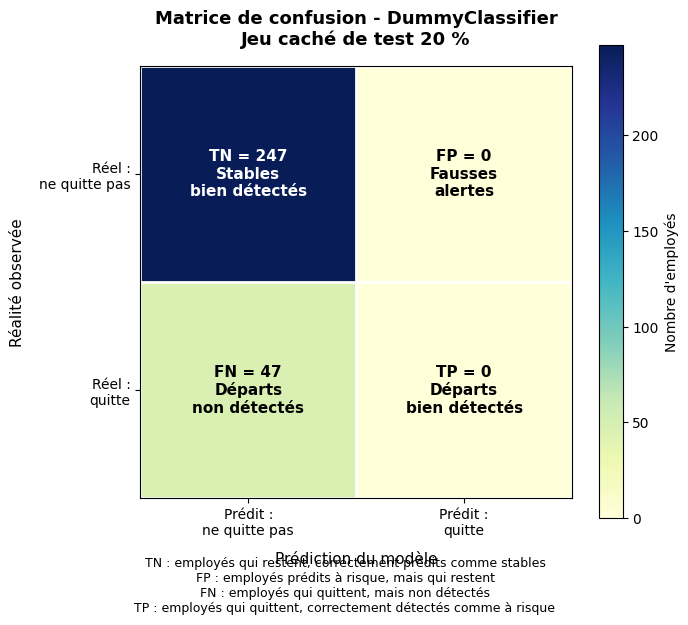

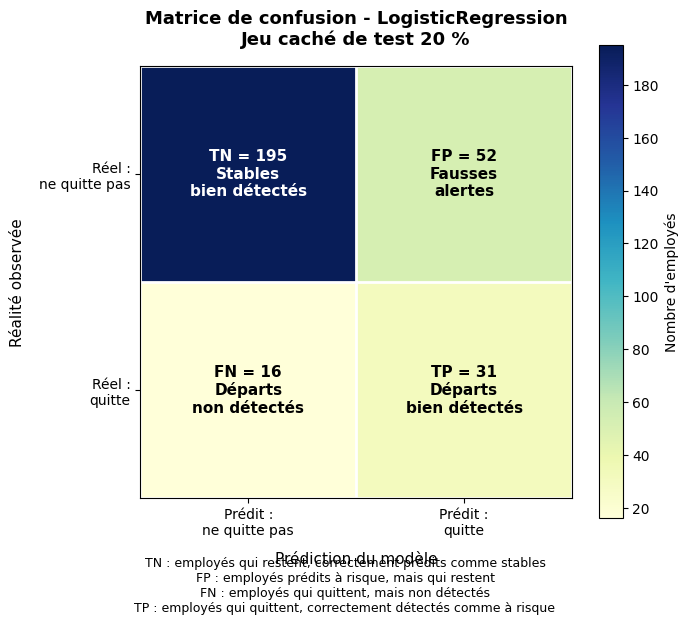

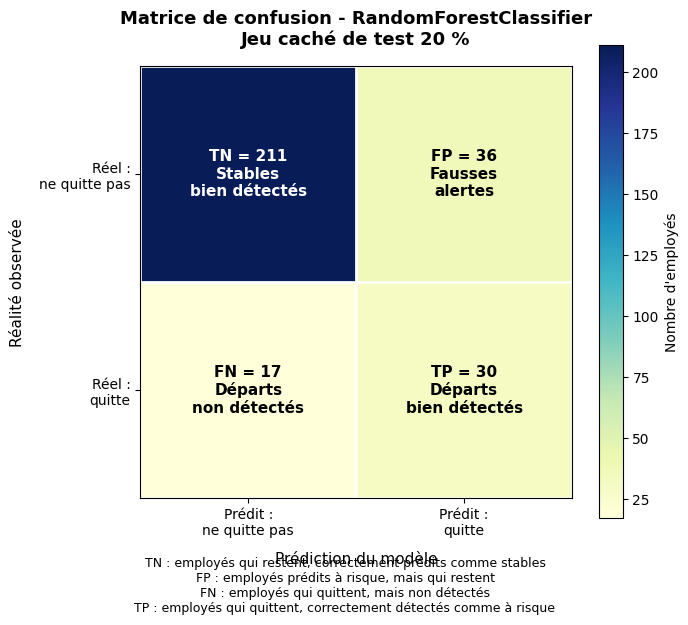

In [19]:

def afficher_matrice_confusion_rh_lisible(y_true, y_pred, nom_modele):
    """
    Affiche une matrice de confusion lisible pour le contexte RH.
    """

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    annotations = np.array([
        [
            f"TN = {tn}\nStables\nbien détectés",
            f"FP = {fp}\nFausses\nalertes"
        ],
        [
            f"FN = {fn}\nDéparts\nnon détectés",
            f"TP = {tp}\nDéparts\nbien détectés"
        ]
    ])

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, cmap="YlGnBu")

    cbar = plt.colorbar(image, ax=ax)
    cbar.set_label("Nombre d'employés", fontsize=10)

    ax.set_title(
        f"Matrice de confusion - {nom_modele}\nJeu caché de test 20 %",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Prédiction du modèle", fontsize=11, labelpad=10)
    ax.set_ylabel("Réalité observée", fontsize=11, labelpad=10)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels([
        "Prédit :\nne quitte pas",
        "Prédit :\nquitte"
    ], fontsize=10)

    ax.set_yticklabels([
        "Réel :\nne quitte pas",
        "Réel :\nquitte"
    ], fontsize=10)

    max_value = cm.max()

    for i in range(2):
        for j in range(2):
            valeur = cm[i, j]
            couleur_texte = "white" if valeur > max_value / 2 else "black"

            ax.text(
                j,
                i,
                annotations[i, j],
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=couleur_texte
            )

    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=2)
    ax.tick_params(which="minor", bottom=False, left=False)

    texte_legende = (
        "TN : employés qui restent, correctement prédits comme stables\n"
        "FP : employés prédits à risque, mais qui restent\n"
        "FN : employés qui quittent, mais non détectés\n"
        "TP : employés qui quittent, correctement détectés comme à risque"
    )

    fig.text(
        0.5,
        -0.04,
        texte_legende,
        ha="center",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()


for nom_modele, modele in modeles_entraines.items():
    y_pred_cache = modele.predict(X_test_cache)
    afficher_matrice_confusion_rh_lisible(
        y_true=y_test_cache,
        y_pred=y_pred_cache,
        nom_modele=nom_modele
    )


## 20. Graphique comparatif des métriques sur le jeu caché

,modele,accuracy,precision,recall,f1_score,f5_score,roc_auc
0,DummyClassifier,0.840,0.000,0.000,0.000,0.000,0.500
1,LogisticRegression,0.769,0.373,0.660,0.477,0.641,0.803
2,RandomForestClassifier,0.820,0.455,0.638,0.531,0.629,0.781


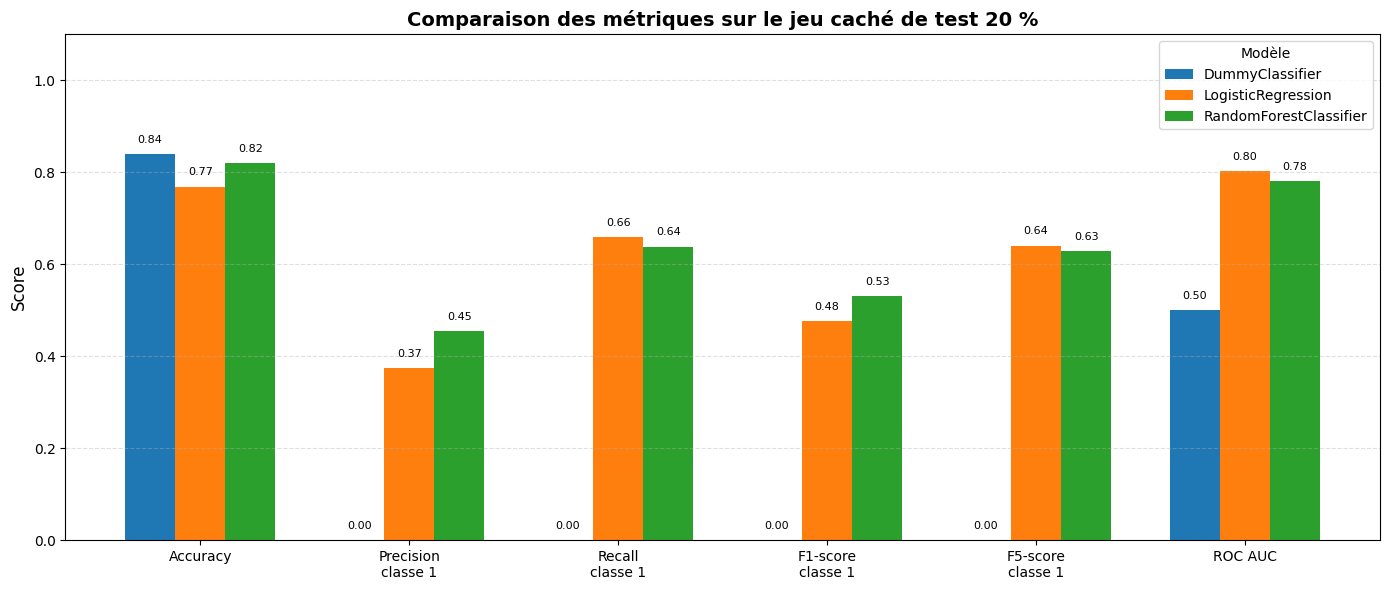

In [20]:

df_metriques_test_cache = (
    df_metriques_train_test
    .query("jeu == 'test_cache_20pct'")
    .drop(columns="jeu")
    .reset_index(drop=True)
)

def graphique_metriques_jeu_cache(df_metriques_test_cache):
    metriques = [
        "accuracy",
        "precision",
        "recall",
        "f1_score",
        "f5_score",
        "roc_auc"
    ]

    labels_metriques = [
        "Accuracy",
        "Precision\nclasse 1",
        "Recall\nclasse 1",
        "F1-score\nclasse 1",
        "F5-score\nclasse 1",
        "ROC AUC"
    ]

    modeles_liste = df_metriques_test_cache["modele"].tolist()

    x = np.arange(len(metriques))
    largeur_barre = 0.24

    fig, ax = plt.subplots(figsize=(14, 6))

    for i, modele in enumerate(modeles_liste):
        valeurs = (
            df_metriques_test_cache
            .loc[df_metriques_test_cache["modele"] == modele, metriques]
            .values
            .flatten()
        )

        ax.bar(
            x + i * largeur_barre,
            valeurs,
            width=largeur_barre,
            label=modele
        )

        for j, valeur in enumerate(valeurs):
            ax.text(
                x[j] + i * largeur_barre,
                valeur + 0.02,
                f"{valeur:.2f}",
                ha="center",
                va="bottom",
                fontsize=8
            )

    ax.set_title(
        "Comparaison des métriques sur le jeu caché de test 20 %",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Score", fontsize=12)
    ax.set_ylim(0, 1.1)

    ax.set_xticks(x + largeur_barre)
    ax.set_xticklabels(labels_metriques, fontsize=10)

    ax.legend(title="Modèle")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


display(df_metriques_test_cache.round(3))
graphique_metriques_jeu_cache(df_metriques_test_cache)



## 21. Cross-validation sur le train uniquement

La cross-validation est réalisée uniquement sur les 80 % d'apprentissage.

Le jeu caché de test de 20 % n'est pas utilisé pendant cette étape.

Comme l'objectif métier est de détecter les employés susceptibles de quitter l'entreprise, on suit en particulier :

- le recall ;
- le F5-score.

Le F5-score est un F-beta score avec `beta=5`. Il donne beaucoup plus de poids au recall qu'à la precision.


In [21]:

f5_scorer = make_scorer(
    fbeta_score,
    beta=5,
    zero_division=0
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1_score": make_scorer(f1_score, zero_division=0),
    "f5_score": f5_scorer,
    "roc_auc": "roc_auc"
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation configurée avec 5 folds stratifiés.")


Cross-validation configurée avec 5 folds stratifiés.


In [22]:

resultats_cv = []

for nom_modele, pipeline in modeles.items():

    print(f"Cross-validation en cours : {nom_modele}")

    scores = cross_validate(
        estimator=pipeline,
        X=X_train_brut,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=None
    )

    for i in range(cv.get_n_splits()):
        resultats_cv.append({
            "modele": nom_modele,
            "fold": i + 1,

            "train_accuracy": scores["train_accuracy"][i],
            "train_precision": scores["train_precision"][i],
            "train_recall": scores["train_recall"][i],
            "train_f1_score": scores["train_f1_score"][i],
            "train_f5_score": scores["train_f5_score"][i],
            "train_roc_auc": scores["train_roc_auc"][i],

            "val_accuracy": scores["test_accuracy"][i],
            "val_precision": scores["test_precision"][i],
            "val_recall": scores["test_recall"][i],
            "val_f1_score": scores["test_f1_score"][i],
            "val_f5_score": scores["test_f5_score"][i],
            "val_roc_auc": scores["test_roc_auc"][i],
        })

df_cv_detail = pd.DataFrame(resultats_cv)

display(df_cv_detail.round(3))


Cross-validation en cours : DummyClassifier
Cross-validation en cours : LogisticRegression
Cross-validation en cours : RandomForestClassifier


,modele,fold,train_accuracy,train_precision,train_recall,train_f1_score,train_f5_score,train_roc_auc,val_accuracy,val_precision,val_recall,val_f1_score,val_f5_score,val_roc_auc
0,DummyClassifier,1,0.838,0.000,0.000,0.000,0.000,0.500,0.839,0.000,0.000,0.000,0.000,0.500
1,DummyClassifier,2,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
2,DummyClassifier,3,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
3,DummyClassifier,4,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
4,DummyClassifier,5,0.838,0.000,0.000,0.000,0.000,0.500,0.838,0.000,0.000,0.000,0.000,0.500
5,LogisticRegression,1,0.791,0.423,0.789,0.550,0.764,0.891,0.809,0.439,0.658,0.526,0.645,0.807
6,LogisticRegression,2,0.800,0.436,0.809,0.567,0.783,0.894,0.757,0.349,0.579,0.436,0.565,0.785
7,LogisticRegression,3,0.791,0.424,0.829,0.561,0.800,0.881,0.749,0.370,0.789,0.504,0.757,0.861
8,LogisticRegression,4,0.768,0.393,0.796,0.526,0.766,0.876,0.774,0.397,0.763,0.523,0.737,0.876
9,LogisticRegression,5,0.792,0.423,0.789,0.550,0.764,0.890,0.745,0.359,0.737,0.483,0.708,0.827


## 22. Synthèse de la cross-validation

In [23]:

df_cv_resume = (
    df_cv_detail
    .groupby("modele")
    .agg(
        train_accuracy_mean=("train_accuracy", "mean"),
        train_accuracy_std=("train_accuracy", "std"),
        val_accuracy_mean=("val_accuracy", "mean"),
        val_accuracy_std=("val_accuracy", "std"),

        train_precision_mean=("train_precision", "mean"),
        train_precision_std=("train_precision", "std"),
        val_precision_mean=("val_precision", "mean"),
        val_precision_std=("val_precision", "std"),

        train_recall_mean=("train_recall", "mean"),
        train_recall_std=("train_recall", "std"),
        val_recall_mean=("val_recall", "mean"),
        val_recall_std=("val_recall", "std"),

        train_f1_mean=("train_f1_score", "mean"),
        train_f1_std=("train_f1_score", "std"),
        val_f1_mean=("val_f1_score", "mean"),
        val_f1_std=("val_f1_score", "std"),

        train_f5_mean=("train_f5_score", "mean"),
        train_f5_std=("train_f5_score", "std"),
        val_f5_mean=("val_f5_score", "mean"),
        val_f5_std=("val_f5_score", "std"),

        train_roc_auc_mean=("train_roc_auc", "mean"),
        train_roc_auc_std=("train_roc_auc", "std"),
        val_roc_auc_mean=("val_roc_auc", "mean"),
        val_roc_auc_std=("val_roc_auc", "std"),
    )
    .reset_index()
)

display(df_cv_resume.round(3))

df_cv_synthese = (
    df_cv_detail
    .groupby("modele")
    .agg(
        accuracy_cv=("val_accuracy", "mean"),
        precision_cv=("val_precision", "mean"),
        recall_cv=("val_recall", "mean"),
        f1_score_cv=("val_f1_score", "mean"),
        f5_score_cv=("val_f5_score", "mean"),
        roc_auc_cv=("val_roc_auc", "mean"),
        f5_score_std=("val_f5_score", "std")
    )
    .reset_index()
    .sort_values(by="f5_score_cv", ascending=False)
)

print("Synthèse orientée validation, triée par F5-score :")
display(df_cv_synthese.round(3))


,modele,train_accuracy_mean,train_accuracy_std,val_accuracy_mean,val_accuracy_std,train_precision_mean,train_precision_std,val_precision_mean,val_precision_std,train_recall_mean,train_recall_std,val_recall_mean,val_recall_std,train_f1_mean,train_f1_std,val_f1_mean,val_f1_std,train_f5_mean,train_f5_std,val_f5_mean,val_f5_std,train_roc_auc_mean,train_roc_auc_std,val_roc_auc_mean,val_roc_auc_std
0,DummyClassifier,0.838,0.000,0.838,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.500,0.000
1,LogisticRegression,0.788,0.012,0.767,0.026,0.420,0.016,0.383,0.036,0.803,0.017,0.705,0.086,0.551,0.016,0.494,0.037,0.775,0.016,0.682,0.078,0.887,0.007,0.831,0.038
2,RandomForestClassifier,0.876,0.006,0.823,0.022,0.603,0.023,0.461,0.049,0.688,0.018,0.458,0.076,0.642,0.008,0.454,0.037,0.684,0.016,0.457,0.072,0.894,0.006,0.780,0.027


Synthèse orientée validation, triée par F5-score :


,modele,accuracy_cv,precision_cv,recall_cv,f1_score_cv,f5_score_cv,roc_auc_cv,f5_score_std
1,LogisticRegression,0.767,0.383,0.705,0.494,0.682,0.831,0.078
2,RandomForestClassifier,0.823,0.461,0.458,0.454,0.457,0.780,0.072
0,DummyClassifier,0.838,0.000,0.000,0.000,0.000,0.500,0.000


## 23. Graphiques de cross-validation

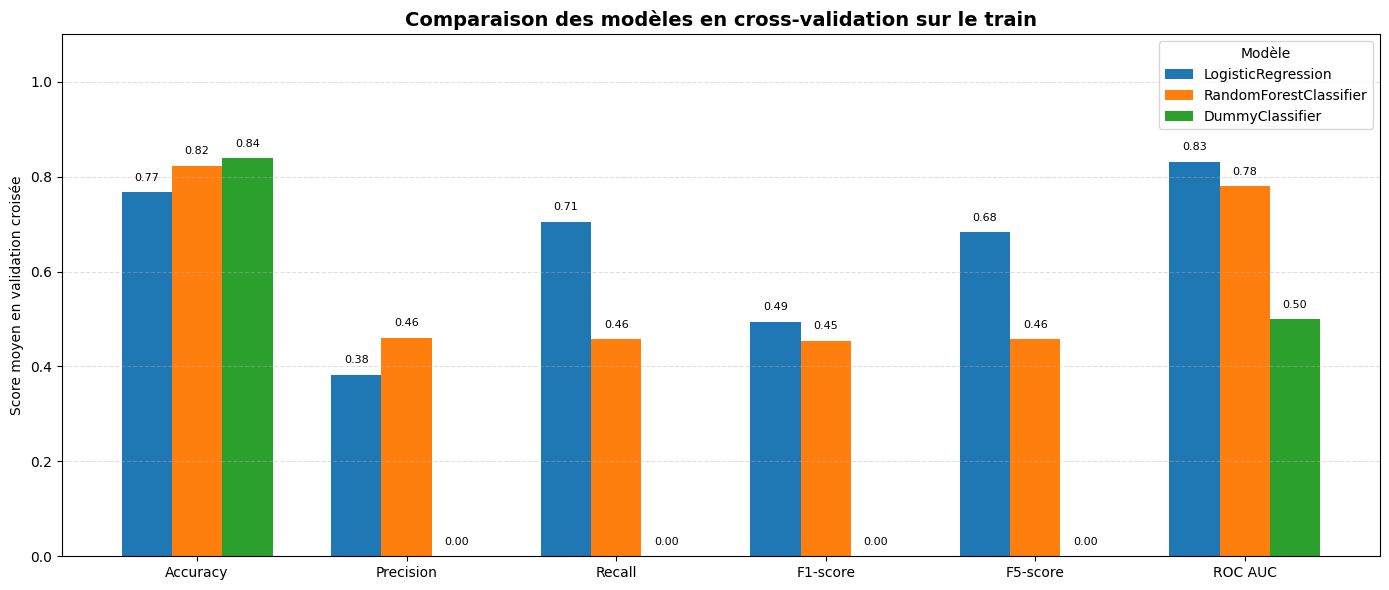

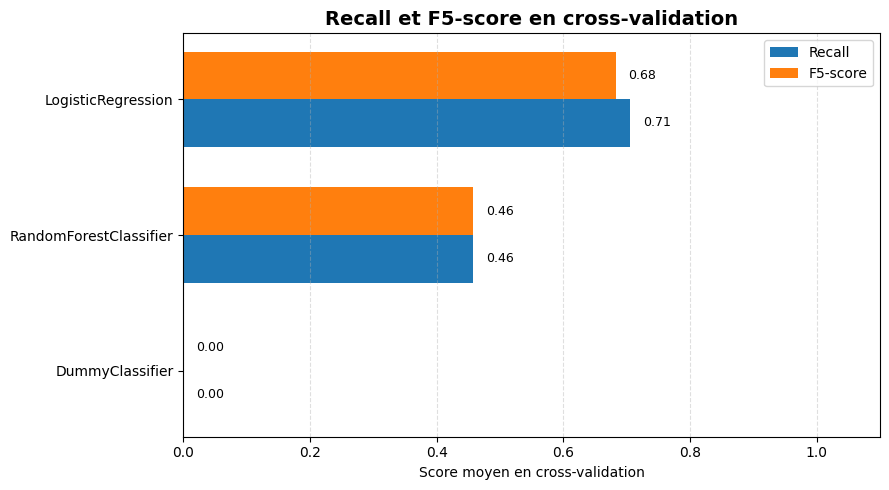

In [24]:

def graphique_cv_metriques(df_cv_synthese):
    metriques = [
        "accuracy_cv",
        "precision_cv",
        "recall_cv",
        "f1_score_cv",
        "f5_score_cv",
        "roc_auc_cv"
    ]

    labels_metriques = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "F5-score",
        "ROC AUC"
    ]

    modeles_liste = df_cv_synthese["modele"].tolist()

    x = np.arange(len(metriques))
    largeur_barre = 0.24

    fig, ax = plt.subplots(figsize=(14, 6))

    for i, modele in enumerate(modeles_liste):
        valeurs = (
            df_cv_synthese
            .loc[df_cv_synthese["modele"] == modele, metriques]
            .values
            .flatten()
        )

        ax.bar(
            x + i * largeur_barre,
            valeurs,
            width=largeur_barre,
            label=modele
        )

        for j, valeur in enumerate(valeurs):
            ax.text(
                x[j] + i * largeur_barre,
                valeur + 0.02,
                f"{valeur:.2f}",
                ha="center",
                va="bottom",
                fontsize=8
            )

    ax.set_title(
        "Comparaison des modèles en cross-validation sur le train",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Score moyen en validation croisée")
    ax.set_ylim(0, 1.1)

    ax.set_xticks(x + largeur_barre)
    ax.set_xticklabels(labels_metriques)

    ax.legend(title="Modèle")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


def graphique_cv_recall_f5(df_cv_synthese):
    df_plot = df_cv_synthese.sort_values(by="f5_score_cv", ascending=True)

    y_pos = np.arange(len(df_plot))
    hauteur_barre = 0.35

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.barh(
        y_pos - hauteur_barre / 2,
        df_plot["recall_cv"],
        height=hauteur_barre,
        label="Recall"
    )

    ax.barh(
        y_pos + hauteur_barre / 2,
        df_plot["f5_score_cv"],
        height=hauteur_barre,
        label="F5-score"
    )

    for i, valeur in enumerate(df_plot["recall_cv"]):
        ax.text(
            valeur + 0.02,
            i - hauteur_barre / 2,
            f"{valeur:.2f}",
            va="center",
            fontsize=9
        )

    for i, valeur in enumerate(df_plot["f5_score_cv"]):
        ax.text(
            valeur + 0.02,
            i + hauteur_barre / 2,
            f"{valeur:.2f}",
            va="center",
            fontsize=9
        )

    ax.set_title(
        "Recall et F5-score en cross-validation",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Score moyen en cross-validation")
    ax.set_xlim(0, 1.1)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_plot["modele"])

    ax.legend()
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


graphique_cv_metriques(df_cv_synthese)
graphique_cv_recall_f5(df_cv_synthese)


## 24. Choix du meilleur modèle selon le F5-score en cross-validation

In [25]:

meilleur_modele_cv = (
    df_cv_synthese
    .sort_values(by="f5_score_cv", ascending=False)
    .iloc[0]
)

print("Meilleur modèle selon le F5-score en cross-validation :")
print(meilleur_modele_cv["modele"])

print("\nScores moyens en cross-validation :")
for metric in ["accuracy_cv", "precision_cv", "recall_cv", "f1_score_cv", "f5_score_cv", "roc_auc_cv"]:
    print(f"{metric} : {round(float(meilleur_modele_cv[metric]), 3)}")


Meilleur modèle selon le F5-score en cross-validation :
LogisticRegression

Scores moyens en cross-validation :
accuracy_cv : 0.767
precision_cv : 0.383
recall_cv : 0.705
f1_score_cv : 0.494
f5_score_cv : 0.682
roc_auc_cv : 0.831



## 25. GridSearchCV sur la régression logistique

Comme la régression logistique est un modèle linéaire performant et interprétable, on réalise une recherche d'hyperparamètres avec `GridSearchCV`.

La recherche est faite uniquement sur :

- `X_train_brut`
- `y_train`

Le jeu caché de test de 20 % n'est pas utilisé pendant l'optimisation.

La métrique optimisée est le F5-score, car elle privilégie le recall.


In [26]:

pipeline_logistique_grid = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("variance_threshold", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

param_grid_logistique = [
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
        "model__solver": ["lbfgs"],
        "model__penalty": ["l2"]
    },
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
        "model__solver": ["liblinear"],
        "model__penalty": ["l1", "l2"]
    }
]

grid_logistique = GridSearchCV(
    estimator=pipeline_logistique_grid,
    param_grid=param_grid_logistique,
    scoring=f5_scorer,
    cv=cv,
    n_jobs=None,
    return_train_score=True
)

grid_logistique.fit(X_train_brut, y_train)

print("Meilleur score F5 en cross-validation :")
print(round(grid_logistique.best_score_, 3))

print("\nMeilleurs hyperparamètres :")
print(grid_logistique.best_params_)


i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to

Meilleur score F5 en cross-validation :
0.756

Meilleurs hyperparamètres :
{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}


i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


## 26. Résultats détaillés du GridSearchCV

In [27]:

df_grid_logistique = pd.DataFrame(grid_logistique.cv_results_)

colonnes_resultats_grid = [
    "param_model__C",
    "param_model__class_weight",
    "param_model__solver",
    "param_model__penalty",
    "mean_train_score",
    "std_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

df_grid_logistique_resultats = (
    df_grid_logistique[colonnes_resultats_grid]
    .sort_values(by="rank_test_score")
    .reset_index(drop=True)
)

display(df_grid_logistique_resultats.round(3).head(20))


,param_model__C,param_model__class_weight,param_model__solver,param_model__penalty,mean_train_score,std_train_score,mean_test_score,std_test_score,rank_test_score
0,0.01,balanced,liblinear,l2,0.797,0.007,0.756,0.048,1
1,0.10,balanced,liblinear,l1,0.784,0.010,0.725,0.062,2
2,0.01,balanced,lbfgs,l2,0.777,0.008,0.721,0.074,3
3,0.10,balanced,liblinear,l2,0.784,0.010,0.711,0.074,4
4,0.10,balanced,lbfgs,l2,0.776,0.013,0.702,0.064,5
5,1.00,balanced,liblinear,l2,0.776,0.013,0.687,0.075,6
6,1.00,balanced,liblinear,l1,0.777,0.014,0.687,0.075,7
7,100.00,balanced,liblinear,l1,0.777,0.010,0.683,0.070,8
8,100.00,balanced,liblinear,l2,0.777,0.010,0.683,0.070,8
9,10.00,balanced,liblinear,l2,0.777,0.010,0.683,0.070,8


## 27. Graphique des meilleurs résultats du GridSearchCV

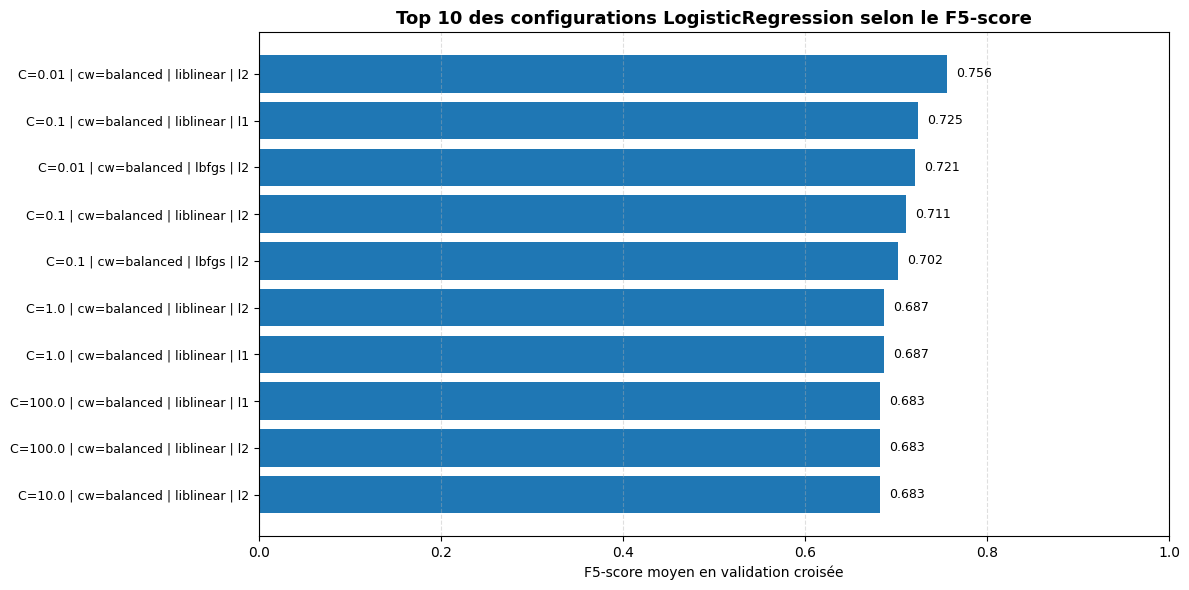

In [28]:

def graphique_top_gridsearch_logistique(df_grid_logistique_resultats, top_n=10):
    df_top = df_grid_logistique_resultats.head(top_n).copy()

    labels = []
    for _, row in df_top.iterrows():
        labels.append(
            f"C={row['param_model__C']} | "
            f"cw={row['param_model__class_weight']} | "
            f"{row['param_model__solver']} | "
            f"{row['param_model__penalty']}"
        )

    y_pos = np.arange(len(df_top))

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.barh(
        y_pos,
        df_top["mean_test_score"]
    )

    for i, valeur in enumerate(df_top["mean_test_score"]):
        ax.text(
            valeur + 0.01,
            i,
            f"{valeur:.3f}",
            va="center",
            fontsize=9
        )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=9)
    ax.invert_yaxis()

    ax.set_xlabel("F5-score moyen en validation croisée")
    ax.set_title(
        f"Top {top_n} des configurations LogisticRegression selon le F5-score",
        fontsize=13,
        fontweight="bold"
    )
    ax.set_xlim(0, max(1.0, df_top["mean_test_score"].max() + 0.1))
    ax.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()


graphique_top_gridsearch_logistique(df_grid_logistique_resultats, top_n=10)



## 28. Évaluation finale de la régression logistique optimisée sur le jeu caché

Le meilleur modèle issu du GridSearchCV est évalué une seule fois sur le jeu caché de 20 %.

C'est cette performance qui doit être utilisée pour conclure sur la capacité de généralisation du modèle optimisé.


In [29]:

meilleur_modele_logistique = grid_logistique.best_estimator_

y_pred_cache_logistique_optimisee = meilleur_modele_logistique.predict(X_test_cache)
y_score_cache_logistique_optimisee = meilleur_modele_logistique.predict_proba(X_test_cache)[:, 1]

resultats_logistique_optimisee = {
    "modele": "LogisticRegression optimisée GridSearchCV",
    "accuracy": accuracy_score(y_test_cache, y_pred_cache_logistique_optimisee),
    "precision": precision_score(y_test_cache, y_pred_cache_logistique_optimisee, zero_division=0),
    "recall": recall_score(y_test_cache, y_pred_cache_logistique_optimisee, zero_division=0),
    "f1_score": f1_score(y_test_cache, y_pred_cache_logistique_optimisee, zero_division=0),
    "f5_score": fbeta_score(y_test_cache, y_pred_cache_logistique_optimisee, beta=5, zero_division=0),
    "roc_auc": roc_auc_score(y_test_cache, y_score_cache_logistique_optimisee)
}

df_resultats_logistique_optimisee = pd.DataFrame([resultats_logistique_optimisee])

display(df_resultats_logistique_optimisee.round(3))

print(classification_report(
    y_test_cache,
    y_pred_cache_logistique_optimisee,
    target_names=[
        "Ne quitte pas l'entreprise",
        "Quitte l'entreprise"
    ],
    zero_division=0
))

print("Matrice de confusion - LogisticRegression optimisée")
print(confusion_matrix(y_test_cache, y_pred_cache_logistique_optimisee, labels=[0, 1]))


,modele,accuracy,precision,recall,f1_score,f5_score,roc_auc
0,LogisticRegression optimisée GridSearchCV,0.752,0.367,0.766,0.497,0.735,0.824


                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.94      0.75      0.84       247
       Quitte l'entreprise       0.37      0.77      0.50        47

                  accuracy                           0.75       294
                 macro avg       0.66      0.76      0.67       294
              weighted avg       0.85      0.75      0.78       294

Matrice de confusion - LogisticRegression optimisée
[[185  62]
 [ 11  36]]


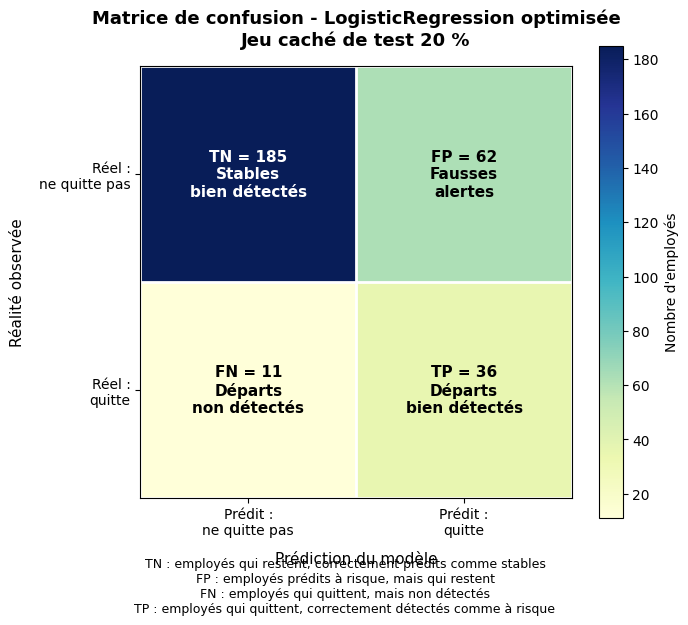

In [30]:

afficher_matrice_confusion_rh_lisible(
    y_true=y_test_cache,
    y_pred=y_pred_cache_logistique_optimisee,
    nom_modele="LogisticRegression optimisée"
)


## 29. Comparaison finale : modèles simples vs régression logistique optimisée

,modele,accuracy,precision,recall,f1_score,f5_score,roc_auc
0,DummyClassifier,0.840,0.000,0.000,0.000,0.000,0.500
1,LogisticRegression,0.769,0.373,0.660,0.477,0.641,0.803
2,RandomForestClassifier,0.820,0.455,0.638,0.531,0.629,0.781
3,LogisticRegression optimisée GridSearchCV,0.752,0.367,0.766,0.497,0.735,0.824


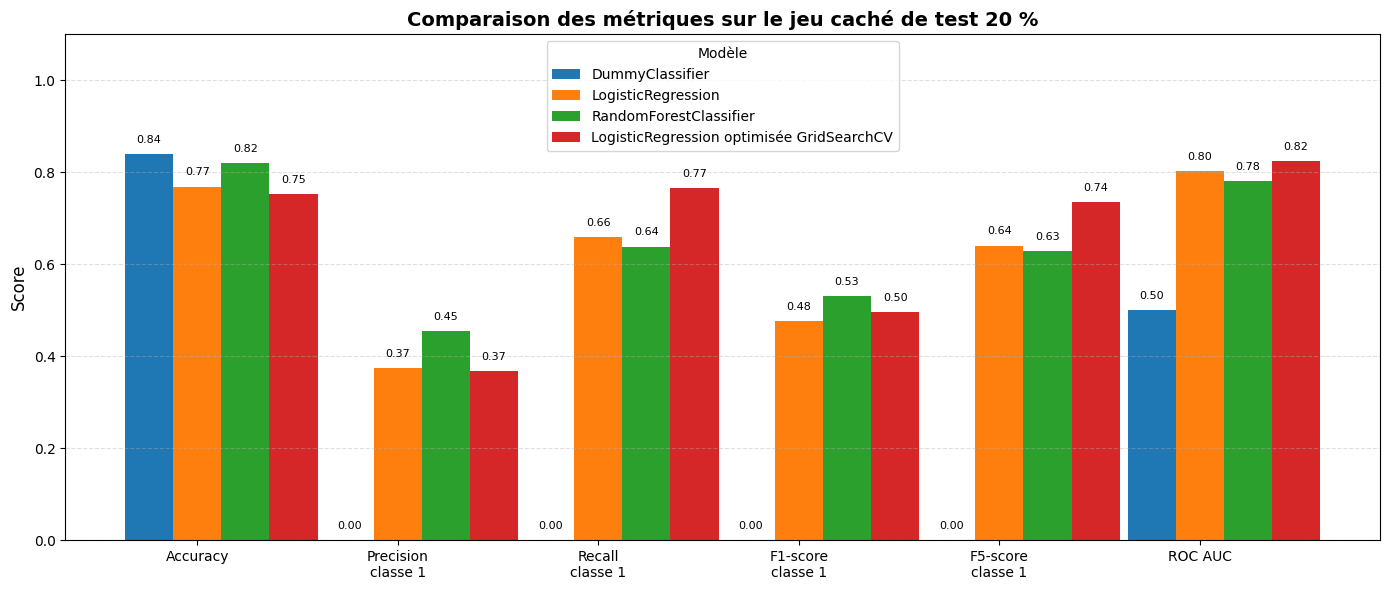

In [31]:

df_comparaison_finale = pd.concat(
    [
        df_metriques_test_cache,
        df_resultats_logistique_optimisee
    ],
    ignore_index=True
)

display(df_comparaison_finale.round(3))

graphique_metriques_jeu_cache(df_comparaison_finale)



## 30. Export des résultats

Les exports sont écrits dans un dossier dédié afin d'éviter les erreurs liées à des fichiers déjà ouverts dans VS Code ou Excel.


In [32]:

dossier_export = Path("exports_notebook_complet_rh")
dossier_export.mkdir(exist_ok=True)

df_central.to_csv(dossier_export / "df_central_rh.csv", index=False)
df_features_detaillees.to_csv(dossier_export / "features_detaillees_apres_preprocessing.csv", index=False)
df_features_finales_conservees.to_csv(dossier_export / "features_finales_conservees.csv", index=False)

df_metriques_train_test.to_csv(dossier_export / "metriques_train_test_diagnostic.csv", index=False)
df_metriques_test_cache.to_csv(dossier_export / "metriques_test_cache_20pct.csv", index=False)

df_cv_detail.to_csv(dossier_export / "cross_validation_detail_folds.csv", index=False)
df_cv_resume.to_csv(dossier_export / "cross_validation_resume_train_val.csv", index=False)
df_cv_synthese.to_csv(dossier_export / "cross_validation_synthese_f5.csv", index=False)

df_grid_logistique_resultats.to_csv(dossier_export / "gridsearch_logistique_resultats.csv", index=False)
df_resultats_logistique_optimisee.to_csv(dossier_export / "resultats_logistique_optimisee_test_cache.csv", index=False)
df_comparaison_finale.to_csv(dossier_export / "comparaison_finale_modeles_test_cache.csv", index=False)

print("Exports terminés dans :", dossier_export)


Exports terminés dans : exports_notebook_complet_rh



## 31. Interprétation synthétique à adapter aux résultats obtenus

Points à commenter dans la conclusion :

1. Le DummyClassifier sert de modèle étalon.
2. L'accuracy seule est insuffisante car les classes sont déséquilibrées.
3. Le recall classe `1` mesure la capacité à détecter les employés qui quittent.
4. La precision classe `1` mesure la fiabilité des alertes RH.
5. Le F1-score équilibre precision et recall.
6. Le F5-score privilégie fortement le recall, ce qui est cohérent si l'entreprise veut éviter de manquer des départs.
7. La cross-validation est utilisée uniquement sur les 80 % du train.
8. Le GridSearchCV de la régression logistique optimise les hyperparamètres uniquement sur le train.
9. Le jeu caché de 20 % est utilisé uniquement à la fin pour mesurer la généralisation.


In [33]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    fbeta_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.base import clone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
try:
    modele_pour_seuil = grid_logistique.best_estimator_
    nom_modele_pour_seuil = "LogisticRegression optimisée GridSearchCV"
except NameError:
    modele_pour_seuil = modeles["LogisticRegression"]
    nom_modele_pour_seuil = "LogisticRegression"

print("Modèle utilisé pour l'optimisation du seuil :")
print(nom_modele_pour_seuil)

Modèle utilisé pour l'optimisation du seuil :
LogisticRegression optimisée GridSearchCV


In [35]:
y_score_train_cv = cross_val_predict(
    estimator=modele_pour_seuil,
    X=X_train_brut,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=None
)[:, 1]

print("Nombre de probabilités prédites en cross-validation :")
print(len(y_score_train_cv))

print("Exemple de probabilités prédites :")
display(pd.Series(y_score_train_cv).head().to_frame("probabilite_classe_1"))

Nombre de probabilités prédites en cross-validation :
1176
Exemple de probabilités prédites :


i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to

,probabilite_classe_1
0,0.158349
1,0.540878
2,0.233402
3,0.674304
4,0.581837


In [36]:
precision, recall, thresholds = precision_recall_curve(
    y_train,
    y_score_train_cv
)

# precision et recall ont une valeur de plus que thresholds.
# On retire donc le dernier point pour aligner les dimensions.
precision_alignee = precision[:-1]
recall_aligne = recall[:-1]

beta = 5

denominateur = (beta**2 * precision_alignee) + recall_aligne

f5_scores = np.where(
    denominateur == 0,
    0,
    (1 + beta**2) * (precision_alignee * recall_aligne) / denominateur
)

df_seuils = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision_alignee,
    "recall": recall_aligne,
    "f5_score": f5_scores
})

df_seuils = df_seuils.sort_values(
    by="f5_score",
    ascending=False
).reset_index(drop=True)

display(df_seuils.head(20).round(3))

,threshold,precision,recall,f5_score
0,0.104,0.166,1.0,0.838
1,0.104,0.166,1.0,0.838
2,0.103,0.166,1.0,0.838
3,0.103,0.166,1.0,0.838
4,0.103,0.166,1.0,0.838
5,0.101,0.165,1.0,0.837
6,0.100,0.165,1.0,0.837
7,0.100,0.165,1.0,0.837
8,0.100,0.165,1.0,0.837
9,0.099,0.165,1.0,0.837


In [37]:
meilleur_seuil = float(df_seuils.loc[0, "threshold"])
meilleur_precision = float(df_seuils.loc[0, "precision"])
meilleur_recall = float(df_seuils.loc[0, "recall"])
meilleur_f5 = float(df_seuils.loc[0, "f5_score"])

print("Seuil optimal selon le F5-score :")
print(round(meilleur_seuil, 3))

print("\nScores associés sur la cross-validation train :")
print("Precision :", round(meilleur_precision, 3))
print("Recall    :", round(meilleur_recall, 3))
print("F5-score  :", round(meilleur_f5, 3))

Seuil optimal selon le F5-score :
0.104

Scores associés sur la cross-validation train :
Precision : 0.166
Recall    : 1.0
F5-score  : 0.838


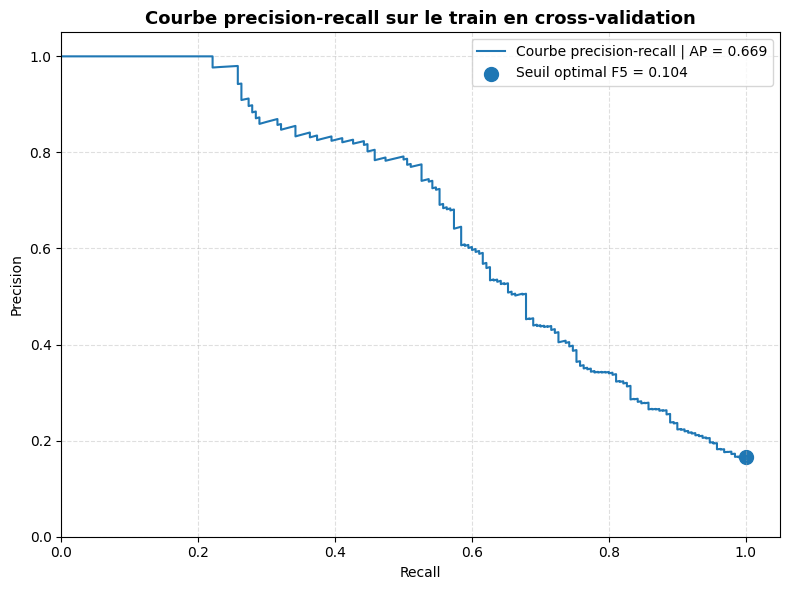

In [38]:
average_precision = average_precision_score(
    y_train,
    y_score_train_cv
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Courbe precision-recall | AP = {average_precision:.3f}"
)

plt.scatter(
    meilleur_recall,
    meilleur_precision,
    s=100,
    label=f"Seuil optimal F5 = {meilleur_seuil:.3f}"
)

plt.title(
    "Courbe precision-recall sur le train en cross-validation",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0, 1.05)
plt.ylim(0, 1.05)

plt.grid(linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

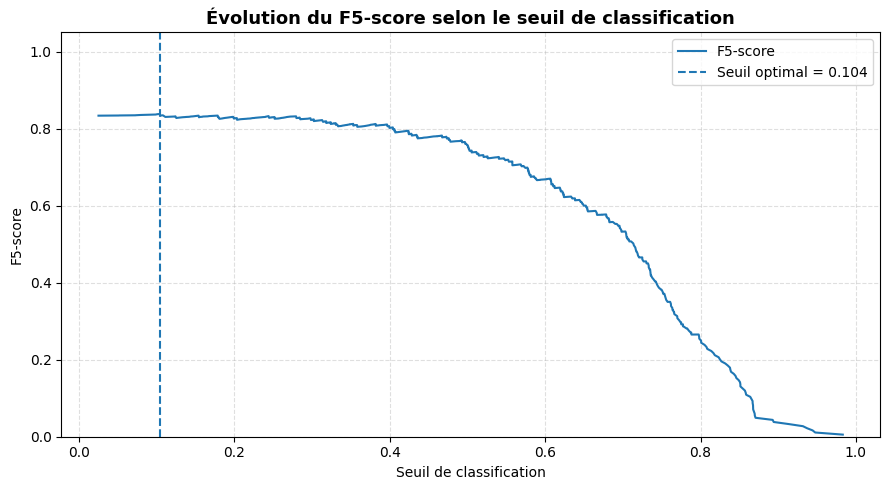

In [39]:
df_seuils_tries = df_seuils.sort_values(by="threshold")

plt.figure(figsize=(9, 5))

plt.plot(
    df_seuils_tries["threshold"],
    df_seuils_tries["f5_score"],
    label="F5-score"
)

plt.axvline(
    meilleur_seuil,
    linestyle="--",
    label=f"Seuil optimal = {meilleur_seuil:.3f}"
)

plt.title(
    "Évolution du F5-score selon le seuil de classification",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Seuil de classification")
plt.ylabel("F5-score")

plt.ylim(0, 1.05)
plt.grid(linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
modele_final_avec_seuil = clone(modele_pour_seuil)

modele_final_avec_seuil.fit(
    X_train_brut,
    y_train
)

print("Modèle final réentraîné sur tout le train.")
print("Seuil retenu :", round(meilleur_seuil, 3))

Modèle final réentraîné sur tout le train.
Seuil retenu : 0.104


i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [41]:
y_score_test_cache = modele_final_avec_seuil.predict_proba(X_test_cache)[:, 1]

y_pred_test_cache_seuil_optimal = (
    y_score_test_cache >= meilleur_seuil
).astype(int)

resultats_seuil_optimal = {
    "modele": nom_modele_pour_seuil,
    "seuil": meilleur_seuil,
    "accuracy": accuracy_score(y_test_cache, y_pred_test_cache_seuil_optimal),
    "precision": precision_score(y_test_cache, y_pred_test_cache_seuil_optimal, zero_division=0),
    "recall": recall_score(y_test_cache, y_pred_test_cache_seuil_optimal, zero_division=0),
    "f1_score": f1_score(y_test_cache, y_pred_test_cache_seuil_optimal, zero_division=0),
    "f5_score": fbeta_score(y_test_cache, y_pred_test_cache_seuil_optimal, beta=5, zero_division=0),
    "roc_auc": roc_auc_score(y_test_cache, y_score_test_cache),
    "average_precision": average_precision_score(y_test_cache, y_score_test_cache)
}

df_resultats_seuil_optimal = pd.DataFrame([resultats_seuil_optimal])

display(df_resultats_seuil_optimal.round(3))

,modele,seuil,accuracy,precision,recall,f1_score,f5_score,roc_auc,average_precision
0,LogisticRegression optimisée GridSearchCV,0.104,0.197,0.161,0.957,0.276,0.805,0.824,0.545


In [42]:
y_pred_test_cache_seuil_05 = (
    y_score_test_cache >= 0.5
).astype(int)

comparaison_seuils = []

for nom_seuil, seuil, y_pred in [
    ("Seuil par défaut 0.5", 0.5, y_pred_test_cache_seuil_05),
    ("Seuil optimisé F5", meilleur_seuil, y_pred_test_cache_seuil_optimal)
]:
    comparaison_seuils.append({
        "seuil_utilise": nom_seuil,
        "valeur_seuil": seuil,
        "accuracy": accuracy_score(y_test_cache, y_pred),
        "precision": precision_score(y_test_cache, y_pred, zero_division=0),
        "recall": recall_score(y_test_cache, y_pred, zero_division=0),
        "f1_score": f1_score(y_test_cache, y_pred, zero_division=0),
        "f5_score": fbeta_score(y_test_cache, y_pred, beta=5, zero_division=0)
    })

df_comparaison_seuils = pd.DataFrame(comparaison_seuils)

display(df_comparaison_seuils.round(3))

,seuil_utilise,valeur_seuil,accuracy,precision,recall,f1_score,f5_score
0,Seuil par défaut 0.5,0.500,0.752,0.367,0.766,0.497,0.735
1,Seuil optimisé F5,0.104,0.197,0.161,0.957,0.276,0.805


In [43]:
print("Classification report avec seuil optimisé :")
print(classification_report(
    y_test_cache,
    y_pred_test_cache_seuil_optimal,
    target_names=[
        "Ne quitte pas l'entreprise",
        "Quitte l'entreprise"
    ],
    zero_division=0
))

print("Matrice de confusion avec seuil optimisé :")
print(confusion_matrix(
    y_test_cache,
    y_pred_test_cache_seuil_optimal,
    labels=[0, 1]
))

Classification report avec seuil optimisé :
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.87      0.05      0.10       247
       Quitte l'entreprise       0.16      0.96      0.28        47

                  accuracy                           0.20       294
                 macro avg       0.51      0.51      0.19       294
              weighted avg       0.75      0.20      0.13       294

Matrice de confusion avec seuil optimisé :
[[ 13 234]
 [  2  45]]


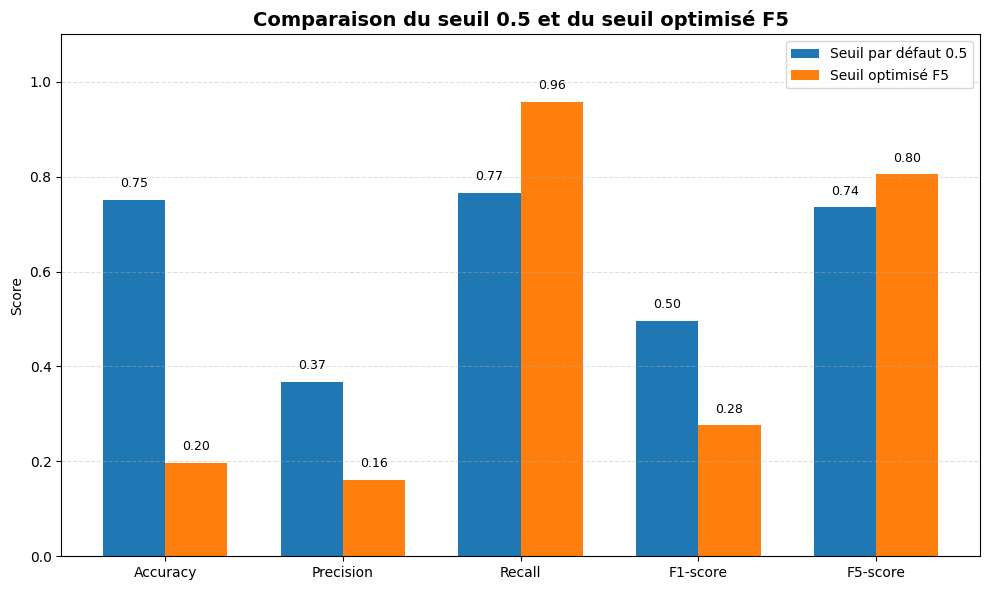

In [44]:
metriques = [
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "f5_score"
]

labels_metriques = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "F5-score"
]

x = np.arange(len(metriques))
largeur_barre = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

for i, seuil_nom in enumerate(df_comparaison_seuils["seuil_utilise"]):
    valeurs = (
        df_comparaison_seuils
        .loc[df_comparaison_seuils["seuil_utilise"] == seuil_nom, metriques]
        .values
        .flatten()
    )
    
    ax.bar(
        x + i * largeur_barre,
        valeurs,
        width=largeur_barre,
        label=seuil_nom
    )
    
    for j, valeur in enumerate(valeurs):
        ax.text(
            x[j] + i * largeur_barre,
            valeur + 0.02,
            f"{valeur:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Comparaison du seuil 0.5 et du seuil optimisé F5",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.1)

ax.set_xticks(x + largeur_barre / 2)
ax.set_xticklabels(labels_metriques)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

L'utilisation de la courbe precision-recall permet d'adapter le seuil de classification au contexte métier.

Le seuil par défaut de `0.5` n'est pas toujours optimal, notamment lorsque les classes sont déséquilibrées.

Dans ce projet RH, l'objectif est de détecter un maximum d'employés susceptibles de quitter l'entreprise. Nous avons donc choisi le seuil qui maximise le F5-score, une métrique qui donne davantage d'importance au recall qu'à la precision.

Le seuil optimal est déterminé uniquement à partir du jeu d'apprentissage via des prédictions en cross-validation, afin d'éviter toute fuite de données.

Le jeu caché de 20 % est utilisé uniquement à la fin pour évaluer la performance réelle du modèle avec ce seuil optimisé.

Matrice de confusion brute :
[[ 13 234]
 [  2  45]]

Lecture :
TN : 13 employés stables correctement prédits comme stables
FP : 234 fausses alertes, prédits à risque mais restent
FN : 2 départs manqués, prédits stables mais quittent
TP : 45 départs correctement détectés


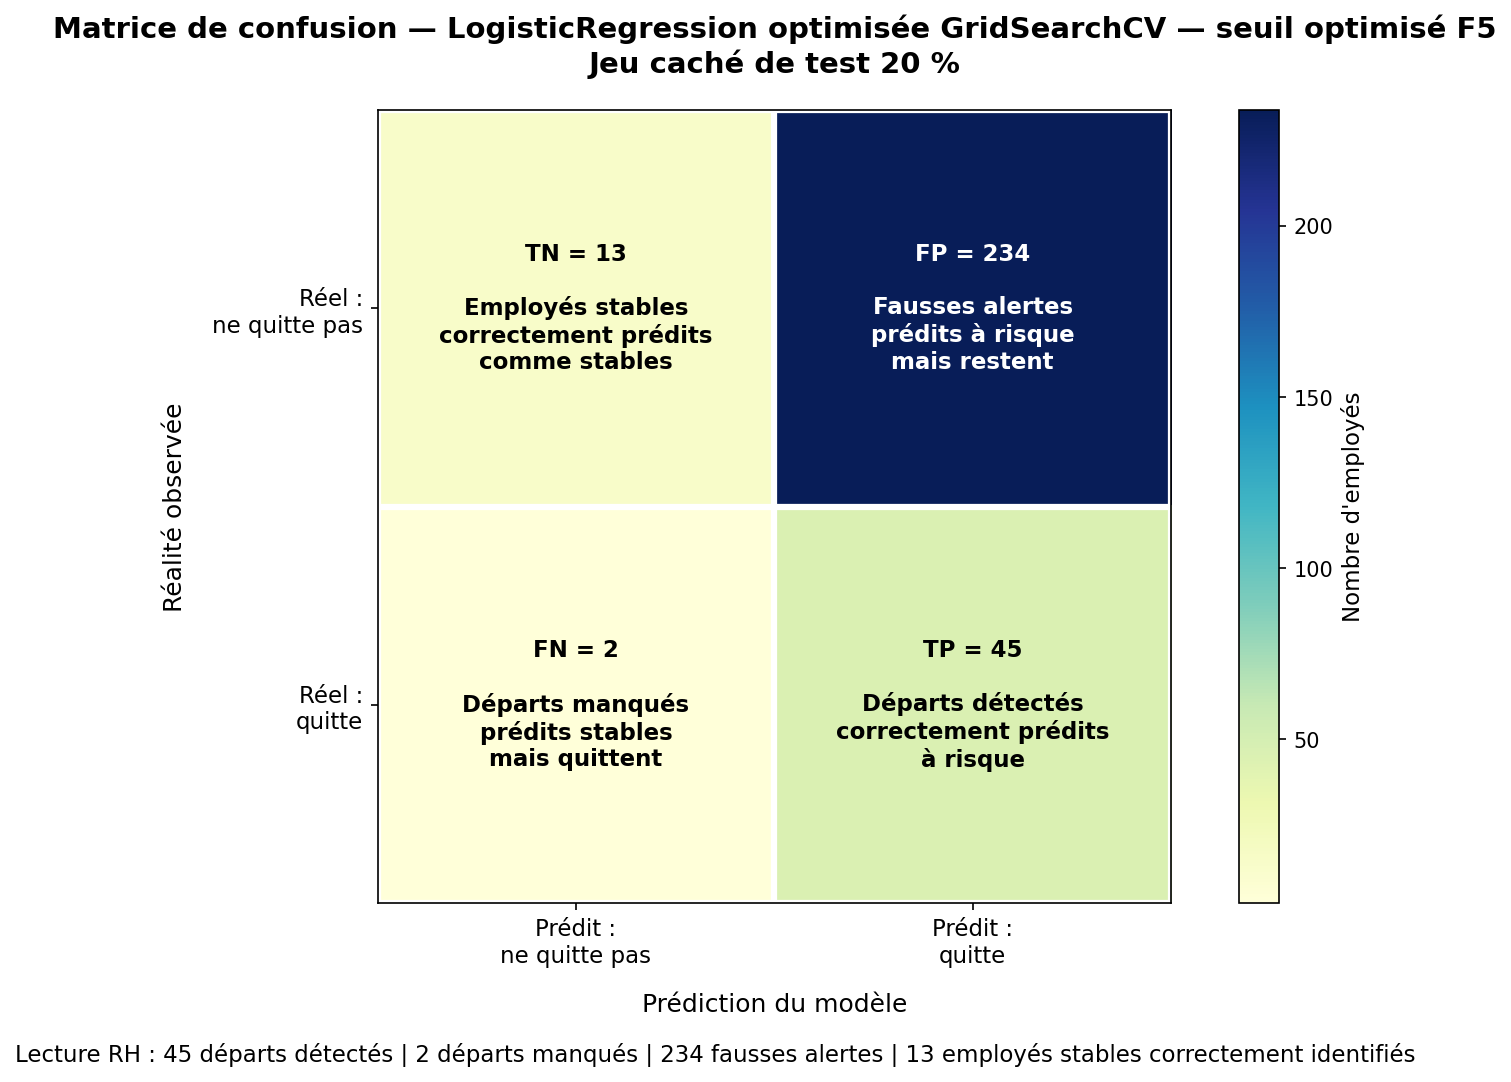

In [45]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, Image
from sklearn.metrics import confusion_matrix


# ============================================================
# 1. Choix automatique des prédictions à afficher
# ============================================================

if "y_pred_test_cache_seuil_optimal" in globals():
    y_pred_a_afficher = y_pred_test_cache_seuil_optimal
    nom_modele_affiche = f"{nom_modele_pour_seuil} — seuil optimisé F5"

elif "modele_final_avec_seuil" in globals() and "meilleur_seuil" in globals():
    y_score_test_cache = modele_final_avec_seuil.predict_proba(X_test_cache)[:, 1]
    y_pred_a_afficher = (y_score_test_cache >= meilleur_seuil).astype(int)
    nom_modele_affiche = f"Modèle final — seuil optimisé F5 = {meilleur_seuil:.3f}"

elif "meilleur_modele_logistique" in globals():
    y_pred_a_afficher = meilleur_modele_logistique.predict(X_test_cache)
    nom_modele_affiche = "LogisticRegression optimisée — seuil 0.5"

elif "modeles_entraines" in globals():
    y_pred_a_afficher = modeles_entraines["LogisticRegression"].predict(X_test_cache)
    nom_modele_affiche = "LogisticRegression — seuil 0.5"

else:
    raise ValueError(
        "Aucun modèle entraîné ou aucune prédiction trouvée. "
        "Exécute d'abord les cellules d'entraînement du modèle."
    )


# ============================================================
# 2. Calcul de la matrice de confusion
# ============================================================

cm = confusion_matrix(
    y_test_cache,
    y_pred_a_afficher,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Matrice de confusion brute :")
print(cm)

print("\nLecture :")
print(f"TN : {tn} employés stables correctement prédits comme stables")
print(f"FP : {fp} fausses alertes, prédits à risque mais restent")
print(f"FN : {fn} départs manqués, prédits stables mais quittent")
print(f"TP : {tp} départs correctement détectés")


# ============================================================
# 3. Affichage graphique explicite
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

image = ax.imshow(cm, cmap="YlGnBu")

cbar = fig.colorbar(image, ax=ax)
cbar.set_label("Nombre d'employés", fontsize=11)

ax.set_title(
    f"Matrice de confusion — {nom_modele_affiche}\nJeu caché de test 20 %",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Prédiction du modèle", fontsize=12, labelpad=12)
ax.set_ylabel("Réalité observée", fontsize=12, labelpad=12)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(
    [
        "Prédit :\nne quitte pas",
        "Prédit :\nquitte"
    ],
    fontsize=11
)

ax.set_yticklabels(
    [
        "Réel :\nne quitte pas",
        "Réel :\nquitte"
    ],
    fontsize=11
)

annotations = [
    [
        f"TN = {tn}\n\nEmployés stables\ncorrectement prédits\ncomme stables",
        f"FP = {fp}\n\nFausses alertes\nprédits à risque\nmais restent"
    ],
    [
        f"FN = {fn}\n\nDéparts manqués\nprédits stables\nmais quittent",
        f"TP = {tp}\n\nDéparts détectés\ncorrectement prédits\nà risque"
    ]
]

valeur_max = cm.max()

for i in range(2):
    for j in range(2):
        couleur_texte = "white" if cm[i, j] > valeur_max / 2 else "black"

        ax.text(
            j,
            i,
            annotations[i][j],
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=couleur_texte
        )

ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

texte_interpretation = (
    f"Lecture RH : "
    f"{tp} départs détectés | "
    f"{fn} départs manqués | "
    f"{fp} fausses alertes | "
    f"{tn} employés stables correctement identifiés"
)

fig.text(
    0.5,
    -0.02,
    texte_interpretation,
    ha="center",
    fontsize=11
)

plt.tight_layout()


# ============================================================
# 4. Affichage robuste : sauvegarde PNG puis affichage de l'image
# ============================================================

chemin_image = Path("matrice_confusion_rh.png")

fig.savefig(
    chemin_image,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

display(Image(filename=str(chemin_image)))

In [46]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, Image


seuil_metier = 0.4

print("Seuil métier retenu :", seuil_metier)

Seuil métier retenu : 0.4


In [47]:
if "grid_logistique" in globals():
    modele_reference_seuil_04 = grid_logistique.best_estimator_
    nom_modele_seuil_04 = "LogisticRegression optimisée GridSearchCV"

elif "meilleur_modele_logistique" in globals():
    modele_reference_seuil_04 = meilleur_modele_logistique
    nom_modele_seuil_04 = "LogisticRegression optimisée"

elif "modeles" in globals() and "LogisticRegression" in modeles:
    modele_reference_seuil_04 = modeles["LogisticRegression"]
    nom_modele_seuil_04 = "LogisticRegression"

else:
    raise ValueError("Aucun modèle de régression logistique disponible.")

print("Modèle utilisé :", nom_modele_seuil_04)

Modèle utilisé : LogisticRegression optimisée GridSearchCV


In [48]:
modele_final_seuil_04 = clone(modele_reference_seuil_04)

modele_final_seuil_04.fit(
    X_train_brut,
    y_train
)

print("Modèle final réentraîné sur tout le train.")
print("Seuil retenu :", seuil_metier)

Modèle final réentraîné sur tout le train.
Seuil retenu : 0.4


i:\OC\P4\projet4\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [49]:
y_score_test_cache_seuil_04 = modele_final_seuil_04.predict_proba(X_test_cache)[:, 1]

y_pred_test_cache_seuil_04 = (
    y_score_test_cache_seuil_04 >= seuil_metier
).astype(int)

display(
    pd.DataFrame({
        "probabilite_depart": y_score_test_cache_seuil_04,
        "prediction_seuil_04": y_pred_test_cache_seuil_04,
        "vraie_classe": y_test_cache.values
    }).head(10)
)

,probabilite_depart,prediction_seuil_04,vraie_classe
0,0.627266,1,0
1,0.155322,0,0
2,0.343868,0,0
3,0.103071,0,0
4,0.651586,1,1
5,0.533422,1,0
6,0.178009,0,0
7,0.227315,0,0
8,0.118622,0,0
9,0.758451,1,0


Seuil métier demandé : 0.4
Seuil réel le plus proche dans la courbe : 0.4
Precision au seuil 0.4 : 0.284
Recall au seuil 0.4 : 0.894
Average precision : 0.545


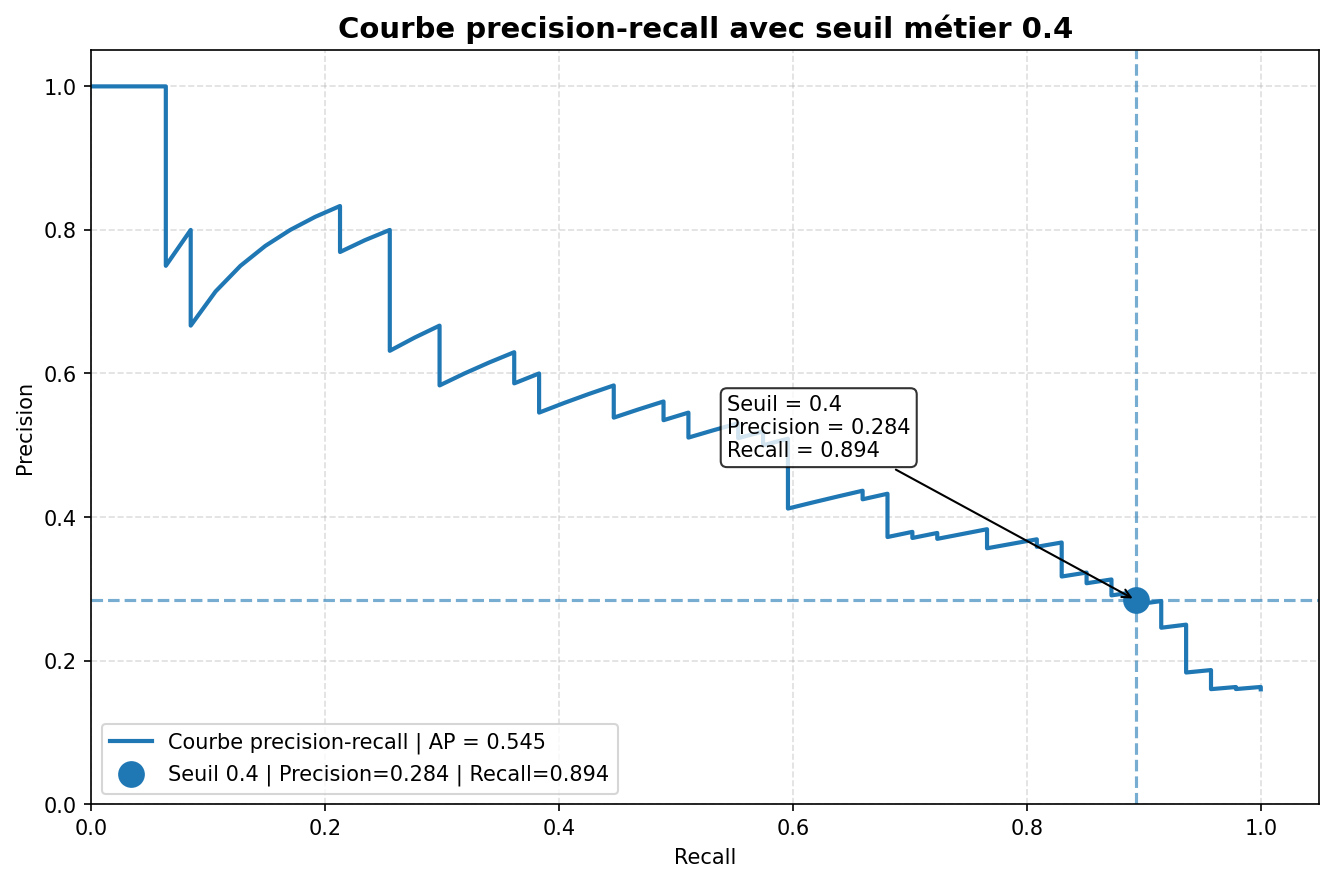

In [50]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from IPython.display import display, Image
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# Courbe precision-recall calculée sur le jeu caché
precision_curve, recall_curve, thresholds_curve = precision_recall_curve(
    y_test_cache,
    y_score_test_cache_seuil_04
)

average_precision = average_precision_score(
    y_test_cache,
    y_score_test_cache_seuil_04
)

# Le tableau thresholds_curve a une longueur inférieure de 1
# à precision_curve et recall_curve.
precision_alignee = precision_curve[:-1]
recall_aligne = recall_curve[:-1]

# Trouver le seuil disponible le plus proche de 0.4
indice_seuil_04 = np.argmin(
    np.abs(thresholds_curve - seuil_metier)
)

precision_seuil_04 = precision_alignee[indice_seuil_04]
recall_seuil_04 = recall_aligne[indice_seuil_04]
seuil_reel_plus_proche = thresholds_curve[indice_seuil_04]

print("Seuil métier demandé :", seuil_metier)
print("Seuil réel le plus proche dans la courbe :", round(float(seuil_reel_plus_proche), 3))
print("Precision au seuil 0.4 :", round(float(precision_seuil_04), 3))
print("Recall au seuil 0.4 :", round(float(recall_seuil_04), 3))
print("Average precision :", round(float(average_precision), 3))


# Graphique
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"Courbe precision-recall | AP = {average_precision:.3f}"
)

ax.scatter(
    recall_seuil_04,
    precision_seuil_04,
    s=140,
    marker="o",
    label=f"Seuil 0.4 | Precision={precision_seuil_04:.3f} | Recall={recall_seuil_04:.3f}"
)

ax.axvline(
    recall_seuil_04,
    linestyle="--",
    alpha=0.6
)

ax.axhline(
    precision_seuil_04,
    linestyle="--",
    alpha=0.6
)

ax.annotate(
    f"Seuil = 0.4\nPrecision = {precision_seuil_04:.3f}\nRecall = {recall_seuil_04:.3f}",
    xy=(recall_seuil_04, precision_seuil_04),
    xytext=(max(recall_seuil_04 - 0.35, 0.05), min(precision_seuil_04 + 0.20, 0.95)),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.8)
)

ax.set_title(
    "Courbe precision-recall avec seuil métier 0.4",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)

ax.grid(linestyle="--", alpha=0.4)
ax.legend(loc="lower left")

plt.tight_layout()

chemin_courbe_pr = Path("courbe_precision_recall_seuil_04.png")

fig.savefig(
    chemin_courbe_pr,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

display(Image(filename=str(chemin_courbe_pr)))

In [51]:
resultats_seuil_04 = {
    "modele": nom_modele_seuil_04,
    "seuil": seuil_metier,
    "accuracy": accuracy_score(y_test_cache, y_pred_test_cache_seuil_04),
    "precision": precision_score(y_test_cache, y_pred_test_cache_seuil_04, zero_division=0),
    "recall": recall_score(y_test_cache, y_pred_test_cache_seuil_04, zero_division=0),
    "f1_score": f1_score(y_test_cache, y_pred_test_cache_seuil_04, zero_division=0),
    "f5_score": fbeta_score(y_test_cache, y_pred_test_cache_seuil_04, beta=5, zero_division=0),
    "roc_auc": roc_auc_score(y_test_cache, y_score_test_cache_seuil_04),
    "average_precision": average_precision_score(y_test_cache, y_score_test_cache_seuil_04)
}

df_resultats_seuil_04 = pd.DataFrame([resultats_seuil_04])

display(df_resultats_seuil_04.round(3))

,modele,seuil,accuracy,precision,recall,f1_score,f5_score,roc_auc,average_precision
0,LogisticRegression optimisée GridSearchCV,0.4,0.626,0.286,0.894,0.433,0.826,0.824,0.545


In [52]:
y_pred_test_cache_seuil_05 = (
    y_score_test_cache_seuil_04 >= 0.5
).astype(int)

comparaison_seuils_04 = []

for nom_seuil, seuil, y_pred in [
    ("Seuil classique 0.5", 0.5, y_pred_test_cache_seuil_05),
    ("Seuil métier 0.4", seuil_metier, y_pred_test_cache_seuil_04)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test_cache,
        y_pred,
        labels=[0, 1]
    ).ravel()

    comparaison_seuils_04.append({
        "seuil_utilise": nom_seuil,
        "valeur_seuil": seuil,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "accuracy": accuracy_score(y_test_cache, y_pred),
        "precision": precision_score(y_test_cache, y_pred, zero_division=0),
        "recall": recall_score(y_test_cache, y_pred, zero_division=0),
        "f1_score": f1_score(y_test_cache, y_pred, zero_division=0),
        "f5_score": fbeta_score(y_test_cache, y_pred, beta=5, zero_division=0)
    })

df_comparaison_seuils_04 = pd.DataFrame(comparaison_seuils_04)

display(df_comparaison_seuils_04.round(3))

,seuil_utilise,valeur_seuil,TN,FP,FN,TP,accuracy,precision,recall,f1_score,f5_score
0,Seuil classique 0.5,0.5,185,62,11,36,0.752,0.367,0.766,0.497,0.735
1,Seuil métier 0.4,0.4,142,105,5,42,0.626,0.286,0.894,0.433,0.826


In [53]:
print("Classification report avec seuil métier 0.4 :")

print(classification_report(
    y_test_cache,
    y_pred_test_cache_seuil_04,
    target_names=[
        "Ne quitte pas l'entreprise",
        "Quitte l'entreprise"
    ],
    zero_division=0
))

Classification report avec seuil métier 0.4 :
                            precision    recall  f1-score   support

Ne quitte pas l'entreprise       0.97      0.57      0.72       247
       Quitte l'entreprise       0.29      0.89      0.43        47

                  accuracy                           0.63       294
                 macro avg       0.63      0.73      0.58       294
              weighted avg       0.86      0.63      0.67       294



Matrice de confusion brute :
[[142 105]
 [  5  42]]

Lecture RH :
TN : 142 employés stables correctement prédits comme stables
FP : 105 fausses alertes, prédits à risque mais restent
FN : 5 départs manqués, prédits stables mais quittent
TP : 42 départs correctement détectés


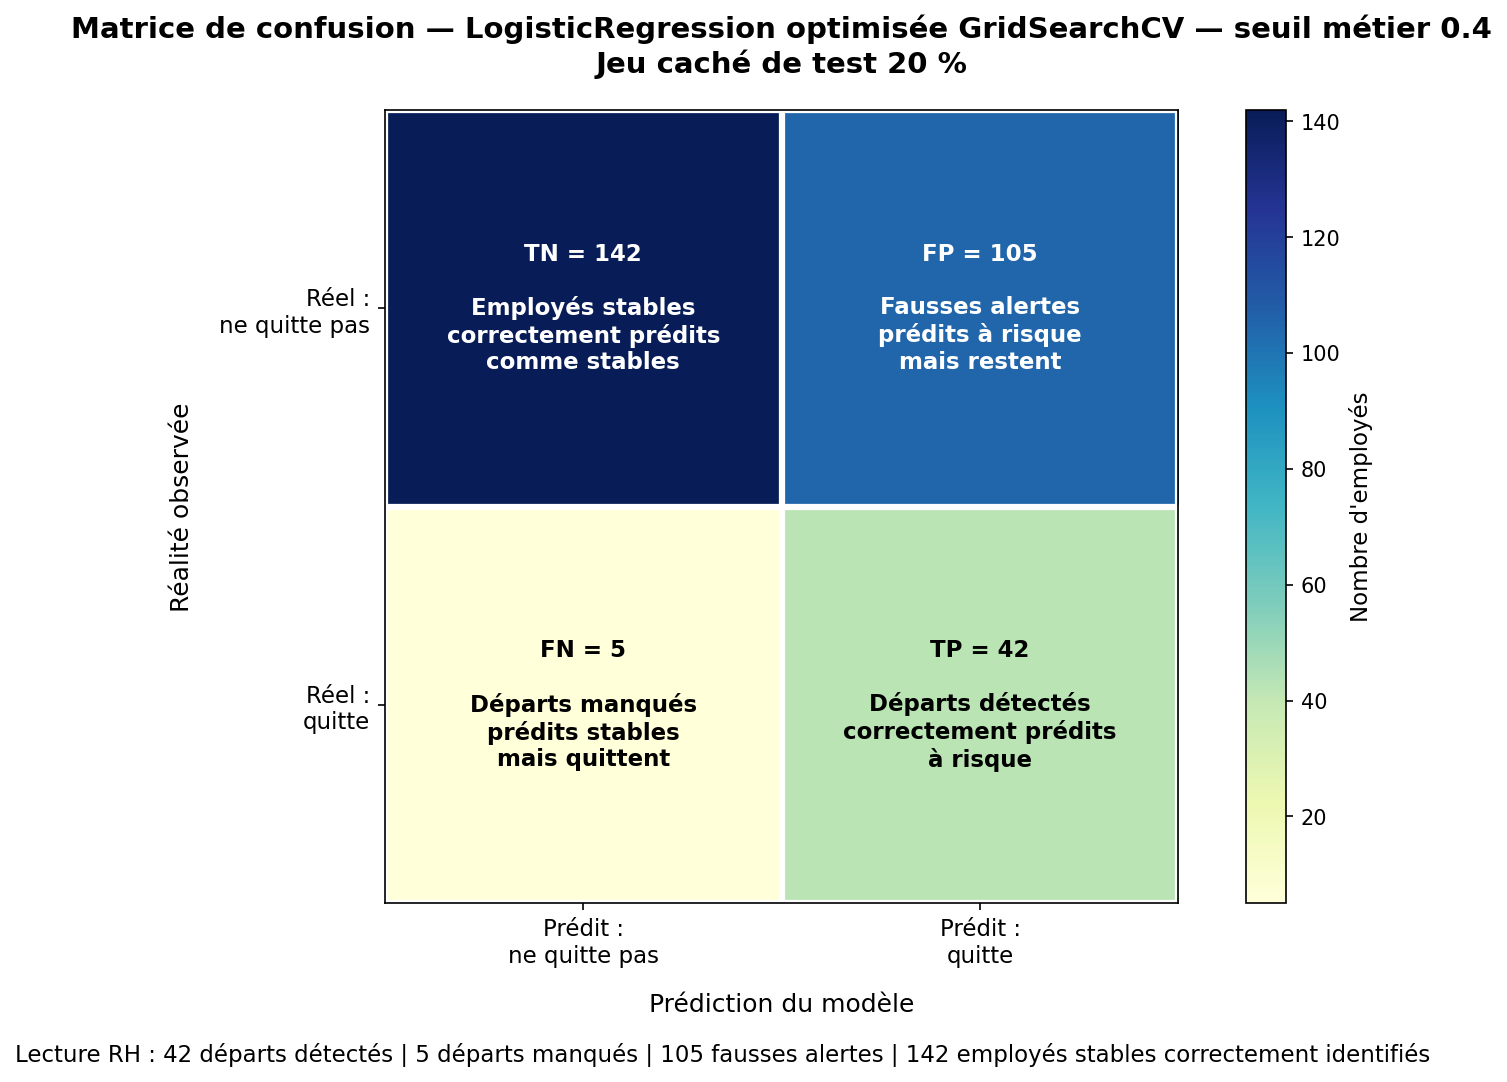

In [54]:
def afficher_matrice_confusion_rh_image(
    y_true,
    y_pred,
    nom_modele,
    chemin_image="matrice_confusion_rh_seuil_04.png"
):
    """
    Génère une matrice de confusion explicite, la sauvegarde en PNG,
    puis l'affiche dans le notebook.
    """

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    print("Matrice de confusion brute :")
    print(cm)

    print("\nLecture RH :")
    print(f"TN : {tn} employés stables correctement prédits comme stables")
    print(f"FP : {fp} fausses alertes, prédits à risque mais restent")
    print(f"FN : {fn} départs manqués, prédits stables mais quittent")
    print(f"TP : {tp} départs correctement détectés")

    fig, ax = plt.subplots(figsize=(10, 7))

    image = ax.imshow(cm, cmap="YlGnBu")

    cbar = fig.colorbar(image, ax=ax)
    cbar.set_label("Nombre d'employés", fontsize=11)

    ax.set_title(
        f"Matrice de confusion — {nom_modele}\nJeu caché de test 20 %",
        fontsize=14,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel("Prédiction du modèle", fontsize=12, labelpad=12)
    ax.set_ylabel("Réalité observée", fontsize=12, labelpad=12)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        [
            "Prédit :\nne quitte pas",
            "Prédit :\nquitte"
        ],
        fontsize=11
    )

    ax.set_yticklabels(
        [
            "Réel :\nne quitte pas",
            "Réel :\nquitte"
        ],
        fontsize=11
    )

    annotations = [
        [
            f"TN = {tn}\n\nEmployés stables\ncorrectement prédits\ncomme stables",
            f"FP = {fp}\n\nFausses alertes\nprédits à risque\nmais restent"
        ],
        [
            f"FN = {fn}\n\nDéparts manqués\nprédits stables\nmais quittent",
            f"TP = {tp}\n\nDéparts détectés\ncorrectement prédits\nà risque"
        ]
    ]

    valeur_max = cm.max()

    for i in range(2):
        for j in range(2):
            couleur_texte = "white" if cm[i, j] > valeur_max / 2 else "black"

            ax.text(
                j,
                i,
                annotations[i][j],
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=couleur_texte
            )

    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    texte_interpretation = (
        f"Lecture RH : "
        f"{tp} départs détectés | "
        f"{fn} départs manqués | "
        f"{fp} fausses alertes | "
        f"{tn} employés stables correctement identifiés"
    )

    fig.text(
        0.5,
        -0.02,
        texte_interpretation,
        ha="center",
        fontsize=11
    )

    plt.tight_layout()

    chemin_image = Path(chemin_image)

    fig.savefig(
        chemin_image,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    display(Image(filename=str(chemin_image)))


afficher_matrice_confusion_rh_image(
    y_true=y_test_cache,
    y_pred=y_pred_test_cache_seuil_04,
    nom_modele=f"{nom_modele_seuil_04} — seuil métier 0.4",
    chemin_image="matrice_confusion_rh_seuil_04.png"
)

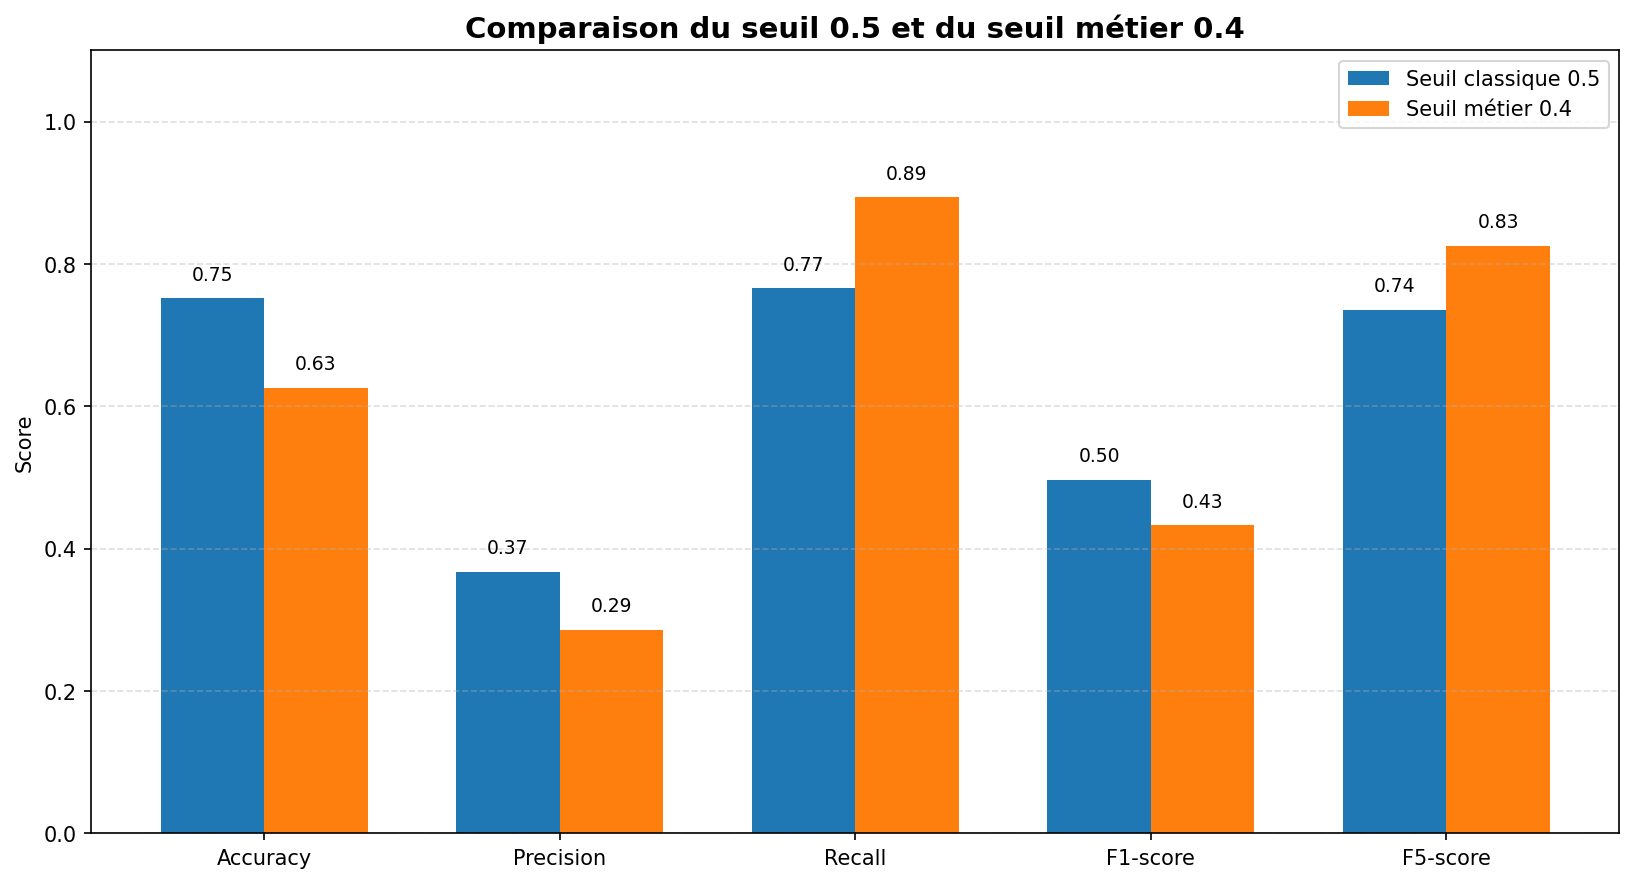

In [55]:
metriques = [
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "f5_score"
]

labels_metriques = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "F5-score"
]

x = np.arange(len(metriques))
largeur_barre = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

for i, seuil_nom in enumerate(df_comparaison_seuils_04["seuil_utilise"]):
    valeurs = (
        df_comparaison_seuils_04
        .loc[df_comparaison_seuils_04["seuil_utilise"] == seuil_nom, metriques]
        .values
        .flatten()
    )

    ax.bar(
        x + i * largeur_barre,
        valeurs,
        width=largeur_barre,
        label=seuil_nom
    )

    for j, valeur in enumerate(valeurs):
        ax.text(
            x[j] + i * largeur_barre,
            valeur + 0.02,
            f"{valeur:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Comparaison du seuil 0.5 et du seuil métier 0.4",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.1)

ax.set_xticks(x + largeur_barre / 2)
ax.set_xticklabels(labels_metriques)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

chemin_graphique_seuils = Path("comparaison_seuil_05_vs_04.png")

fig.savefig(
    chemin_graphique_seuils,
    dpi=150,
    bbox_inches="tight"
)

plt.close(fig)

display(Image(filename=str(chemin_graphique_seuils)))

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display, Image

from sklearn.inspection import permutation_importance
from sklearn.metrics import fbeta_score, precision_score, recall_score, confusion_matrix

import shap

i:\OC\P4\projet4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [57]:
if "modele_final_seuil_04" in globals():
    modele_explicabilite = modele_final_seuil_04
    nom_modele_explicabilite = "LogisticRegression optimisée — seuil 0.4"

elif "grid_logistique" in globals():
    modele_explicabilite = grid_logistique.best_estimator_
    nom_modele_explicabilite = "LogisticRegression optimisée GridSearchCV"

elif "meilleur_modele_logistique" in globals():
    modele_explicabilite = meilleur_modele_logistique
    nom_modele_explicabilite = "LogisticRegression optimisée"

elif "modeles_entraines" in globals() and "LogisticRegression" in modeles_entraines:
    modele_explicabilite = modeles_entraines["LogisticRegression"]
    nom_modele_explicabilite = "LogisticRegression"

else:
    raise ValueError("Aucun modèle de régression logistique entraîné n'a été trouvé.")

print("Modèle expliqué :", nom_modele_explicabilite)

Modèle expliqué : LogisticRegression optimisée — seuil 0.4


In [58]:
if "seuil_metier" in globals():
    seuil_explicabilite = seuil_metier
else:
    seuil_explicabilite = 0.4

print("Seuil utilisé pour interpréter les prédictions :", seuil_explicabilite)

Seuil utilisé pour interpréter les prédictions : 0.4


## Interprétabilité du modèle : feature importance globale et locale

Nous commençons par analyser l'importance globale des variables.

Deux méthodes sont comparées :

1. **Permutation Importance sklearn**  
   Elle mesure la baisse de performance du modèle lorsque les valeurs d'une variable sont mélangées.

2. **SHAP Beeswarm Plot**  
   Il montre, pour chaque variable, la distribution des contributions SHAP sur les observations.

Ensuite, nous analysons les points de convergence et de divergence entre ces deux méthodes.

Enfin, nous passons à l'interprétabilité locale avec des Waterfall Plots, afin d'expliquer quelques prédictions individuelles issues des deux classes.

Permutation Importance sklearn

Ici, on calcule l’importance globale des variables brutes : age, revenu_mensuel, poste, departement, etc.

La métrique utilisée est le F5-score avec le seuil choisi.

In [59]:
def score_f5_avec_seuil(estimator, X, y):
    """
    Score F5 calculé avec un seuil personnalisé.
    Cela permet d'évaluer l'importance des variables
    selon le même seuil métier que celui utilisé pour classifier.
    """
    
    y_score = estimator.predict_proba(X)[:, 1]
    y_pred = (y_score >= seuil_explicabilite).astype(int)
    
    return fbeta_score(
        y,
        y_pred,
        beta=5,
        zero_division=0
    )


resultat_permutation = permutation_importance(
    estimator=modele_explicabilite,
    X=X_test_cache,
    y=y_test_cache,
    scoring=score_f5_avec_seuil,
    n_repeats=30,
    random_state=42,
    n_jobs=None
)

df_permutation_importance = pd.DataFrame({
    "variable_originale": X_test_cache.columns,
    "importance_moyenne_permutation": resultat_permutation.importances_mean,
    "importance_std_permutation": resultat_permutation.importances_std
})

df_permutation_importance = (
    df_permutation_importance
    .sort_values(by="importance_moyenne_permutation", ascending=False)
    .reset_index(drop=True)
)

display(df_permutation_importance.round(4).head(20))

,variable_originale,importance_moyenne_permutation,importance_std_permutation
0,heure_supplementaires,0.0909,0.0168
1,ratio_temps_poste_anciennete,0.0474,0.0252
2,nombre_experiences_precedentes,0.0374,0.0170
3,satisfaction_employee_environnement,0.0327,0.0283
4,statut_marital,0.0326,0.0186
5,satisfaction_employee_equilibre_pro_perso,0.0299,0.0171
6,nombre_participation_pee,0.0275,0.0184
7,satisfaction_employee_nature_travail,0.0269,0.0225
8,poste,0.0245,0.0259
9,nb_formations_suivies,0.0208,0.0145


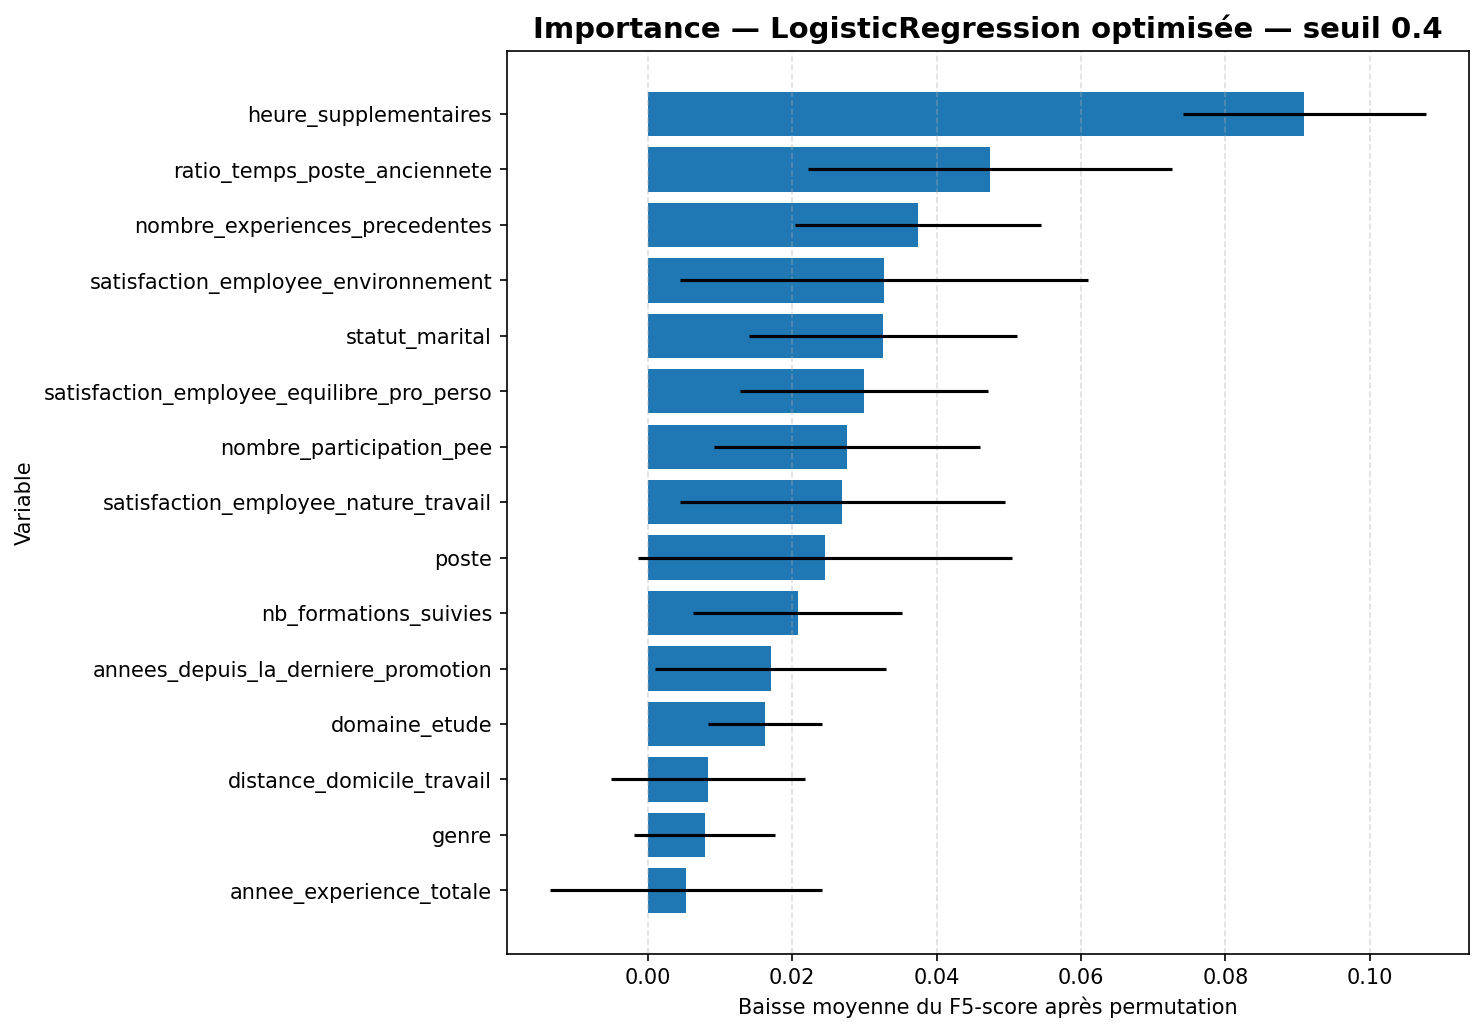

In [60]:
top_n = 15

df_perm_top = (
    df_permutation_importance
    .head(top_n)
    .sort_values(by="importance_moyenne_permutation", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    df_perm_top["variable_originale"],
    df_perm_top["importance_moyenne_permutation"],
    xerr=df_perm_top["importance_std_permutation"]
)

ax.set_title(
    f"Importance — {nom_modele_explicabilite}",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Baisse moyenne du F5-score après permutation")
ax.set_ylabel("Variable")

ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

chemin_perm = Path("permutation_importance_f5.png")
fig.savefig(chemin_perm, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(chemin_perm)))

In [61]:
def transformer_X_pour_modele_interne(pipeline, X):
    """
    Transforme X avec les étapes du pipeline avant le modèle final.

    Retourne un DataFrame avec les noms des features après preprocessing.
    """
    
    # 1. Preprocessing : imputation + one-hot
    X_transforme = pipeline.named_steps["preprocessing"].transform(X)
    noms_features = pipeline.named_steps["preprocessing"].get_feature_names_out()
    
    # 2. Suppression des colonnes constantes
    masque_variance = pipeline.named_steps["variance_threshold"].get_support()
    X_transforme = X_transforme[:, masque_variance]
    noms_features = noms_features[masque_variance]
    
    # 3. Scaling si présent dans le pipeline
    if "scaler" in pipeline.named_steps:
        X_transforme = pipeline.named_steps["scaler"].transform(X_transforme)
    
    X_transforme_df = pd.DataFrame(
        X_transforme,
        columns=noms_features,
        index=X.index
    )
    
    return X_transforme_df


X_train_shap = transformer_X_pour_modele_interne(
    modele_explicabilite,
    X_train_brut
)

X_test_shap = transformer_X_pour_modele_interne(
    modele_explicabilite,
    X_test_cache
)

modele_interne = modele_explicabilite.named_steps["model"]

print("Dimensions X_train_shap :", X_train_shap.shape)
print("Dimensions X_test_shap :", X_test_shap.shape)

display(X_test_shap.head())

Dimensions X_train_shap : (1176, 45)
Dimensions X_test_shap : (294, 45)


,numerique__age,numerique__revenu_mensuel,numerique__nombre_experiences_precedentes,numerique__annee_experience_totale,numerique__annees_dans_l_entreprise,numerique__annees_dans_le_poste_actuel,numerique__satisfaction_employee_environnement,numerique__note_evaluation_precedente,numerique__niveau_hierarchique_poste,numerique__satisfaction_employee_nature_travail,numerique__satisfaction_employee_equipe,numerique__satisfaction_employee_equilibre_pro_perso,numerique__note_evaluation_actuelle,numerique__nombre_participation_pee,numerique__nb_formations_suivies,numerique__distance_domicile_travail,numerique__niveau_education,numerique__annees_depuis_la_derniere_promotion,numerique__annes_sous_responsable_actuel,numerique__augmentation_salaire_precedente_pct,numerique__ratio_anciennete_experience,numerique__ratio_temps_poste_anciennete,numerique__ratio_promotion_anciennete,numerique__revenu_par_annee_experience,categoriel__genre_M,categoriel__statut_marital_Divorcé(e),categoriel__statut_marital_Marié(e),categoriel__departement_Consulting,categoriel__departement_Ressources Humaines,categoriel__poste_Cadre Commercial,categoriel__poste_Consultant,categoriel__poste_Directeur Technique,categoriel__poste_Manager,categoriel__poste_Représentant Commercial,categoriel__poste_Ressources Humaines,categoriel__poste_Senior Manager,categoriel__poste_Tech Lead,categoriel__heure_supplementaires_Oui,categoriel__domaine_etude_Entrepreunariat,categoriel__domaine_etude_Infra & Cloud,categoriel__domaine_etude_Marketing,categoriel__domaine_etude_Ressources Humaines,categoriel__domaine_etude_Transformation Digitale,categoriel__frequence_deplacement_Frequent,categoriel__frequence_deplacement_Occasionnel
1061,-1.416826,-0.969745,-0.681293,-1.329148,-0.994436,-1.185905,1.179114,0.373564,-0.986265,-0.647997,0.240218,0.337621,-0.432065,0.247430,-0.605389,0.445433,-0.882152,-0.679165,-1.177687,-0.609051,0.980071,-1.754692,-0.849021,-0.086549,-1.221280,-0.536713,1.085255,-1.361752,-0.206284,-0.549841,-0.472996,-0.237915,-0.317999,4.312772,-0.190061,-0.275568,-0.326041,-0.637729,-0.329224,1.206281,-0.358607,-0.138073,-0.669534,-0.486408,-1.542501
891,0.763191,-0.974474,-0.681293,-0.175017,0.484849,0.215446,-1.577622,1.795282,-0.986265,1.153526,1.160403,0.337621,-0.432065,0.247430,1.783664,-0.899915,-1.855332,1.498820,0.786795,-0.609051,0.980071,-0.243057,1.211630,-0.086549,-1.221280,-0.536713,1.085255,0.734348,-0.206284,-0.549841,-0.472996,-0.237915,-0.317999,-0.231869,-0.190061,-0.275568,-0.326041,-0.637729,-0.329224,1.206281,-0.358607,-0.138073,-0.669534,-0.486408,0.648298
456,-0.653820,1.077650,2.537997,-0.175017,-0.336976,-0.064824,0.260202,-1.048155,0.846038,1.153526,0.240218,-1.055510,2.314467,0.247430,0.190962,-0.288393,0.091029,-0.679165,-0.897047,1.566330,-0.553107,0.663923,-0.849021,-0.086549,0.818813,1.863192,-0.921443,-1.361752,-0.206284,-0.549841,-0.472996,-0.237915,-0.317999,-0.231869,-0.190061,3.628867,-0.326041,-0.637729,-0.329224,1.206281,-0.358607,-0.138073,-0.669534,-0.486408,0.648298
922,0.763191,2.718533,-0.681293,1.876772,2.950322,1.336527,0.260202,1.795282,2.678340,-1.548758,1.160403,-1.055510,-0.432065,1.430265,0.987313,-0.655306,-0.882152,3.676804,2.470637,-0.337129,0.862134,-0.666315,0.799500,-0.086549,0.818813,1.863192,-0.921443,0.734348,-0.206284,-0.549841,-0.472996,-0.237915,-0.317999,-0.231869,-0.190061,3.628867,-0.326041,-0.637729,-0.329224,1.206281,-0.358607,-0.138073,-0.669534,-0.486408,0.648298
69,-0.108815,-0.678457,-1.083704,-1.200911,-0.994436,-1.185905,1.179114,-1.048155,-0.986265,0.252765,-1.600151,-1.055510,-0.432065,0.247430,-2.198092,-0.043784,0.091029,-0.679165,-1.177687,0.478639,-0.553107,-1.754692,-0.849021,-0.086549,0.818813,-0.536713,1.085255,0.734348,-0.206284,-0.549841,-0.472996,-0.237915,-0.317999,-0.231869,-0.190061,-0.275568,-0.326041,1.568064,-0.329224,-0.828994,-0.358607,-0.138073,1.493576,-0.486408,0.648298


SHAP value positive  → pousse la prédiction vers la classe 1 : départ
SHAP value négative  → pousse la prédiction vers la classe 0 : stabilité

In [62]:
explainer = shap.Explainer(
    modele_interne,
    X_train_shap
)

shap_values = explainer(X_test_shap)

# Gestion au cas où SHAP retourne une dimension supplémentaire
if len(shap_values.values.shape) == 3:
    shap_values_classe_1 = shap_values[:, :, 1]
else:
    shap_values_classe_1 = shap_values

print("SHAP values calculées.")
print("Shape :", shap_values_classe_1.values.shape)

Background dataset has 1176 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1176 when initializing the masker.


SHAP values calculées.
Shape : (294, 45)


Beeswarm Plot SHAP global

Le beeswarm montre :

en ordonnée : les variables les plus importantes ;
en abscisse : l’impact SHAP sur la prédiction ;
en couleur : la valeur de la variable, faible ou élevée.

Importance globale SHAP

On calcule ici l’importance globale SHAP comme la moyenne des valeurs absolues SHAP.

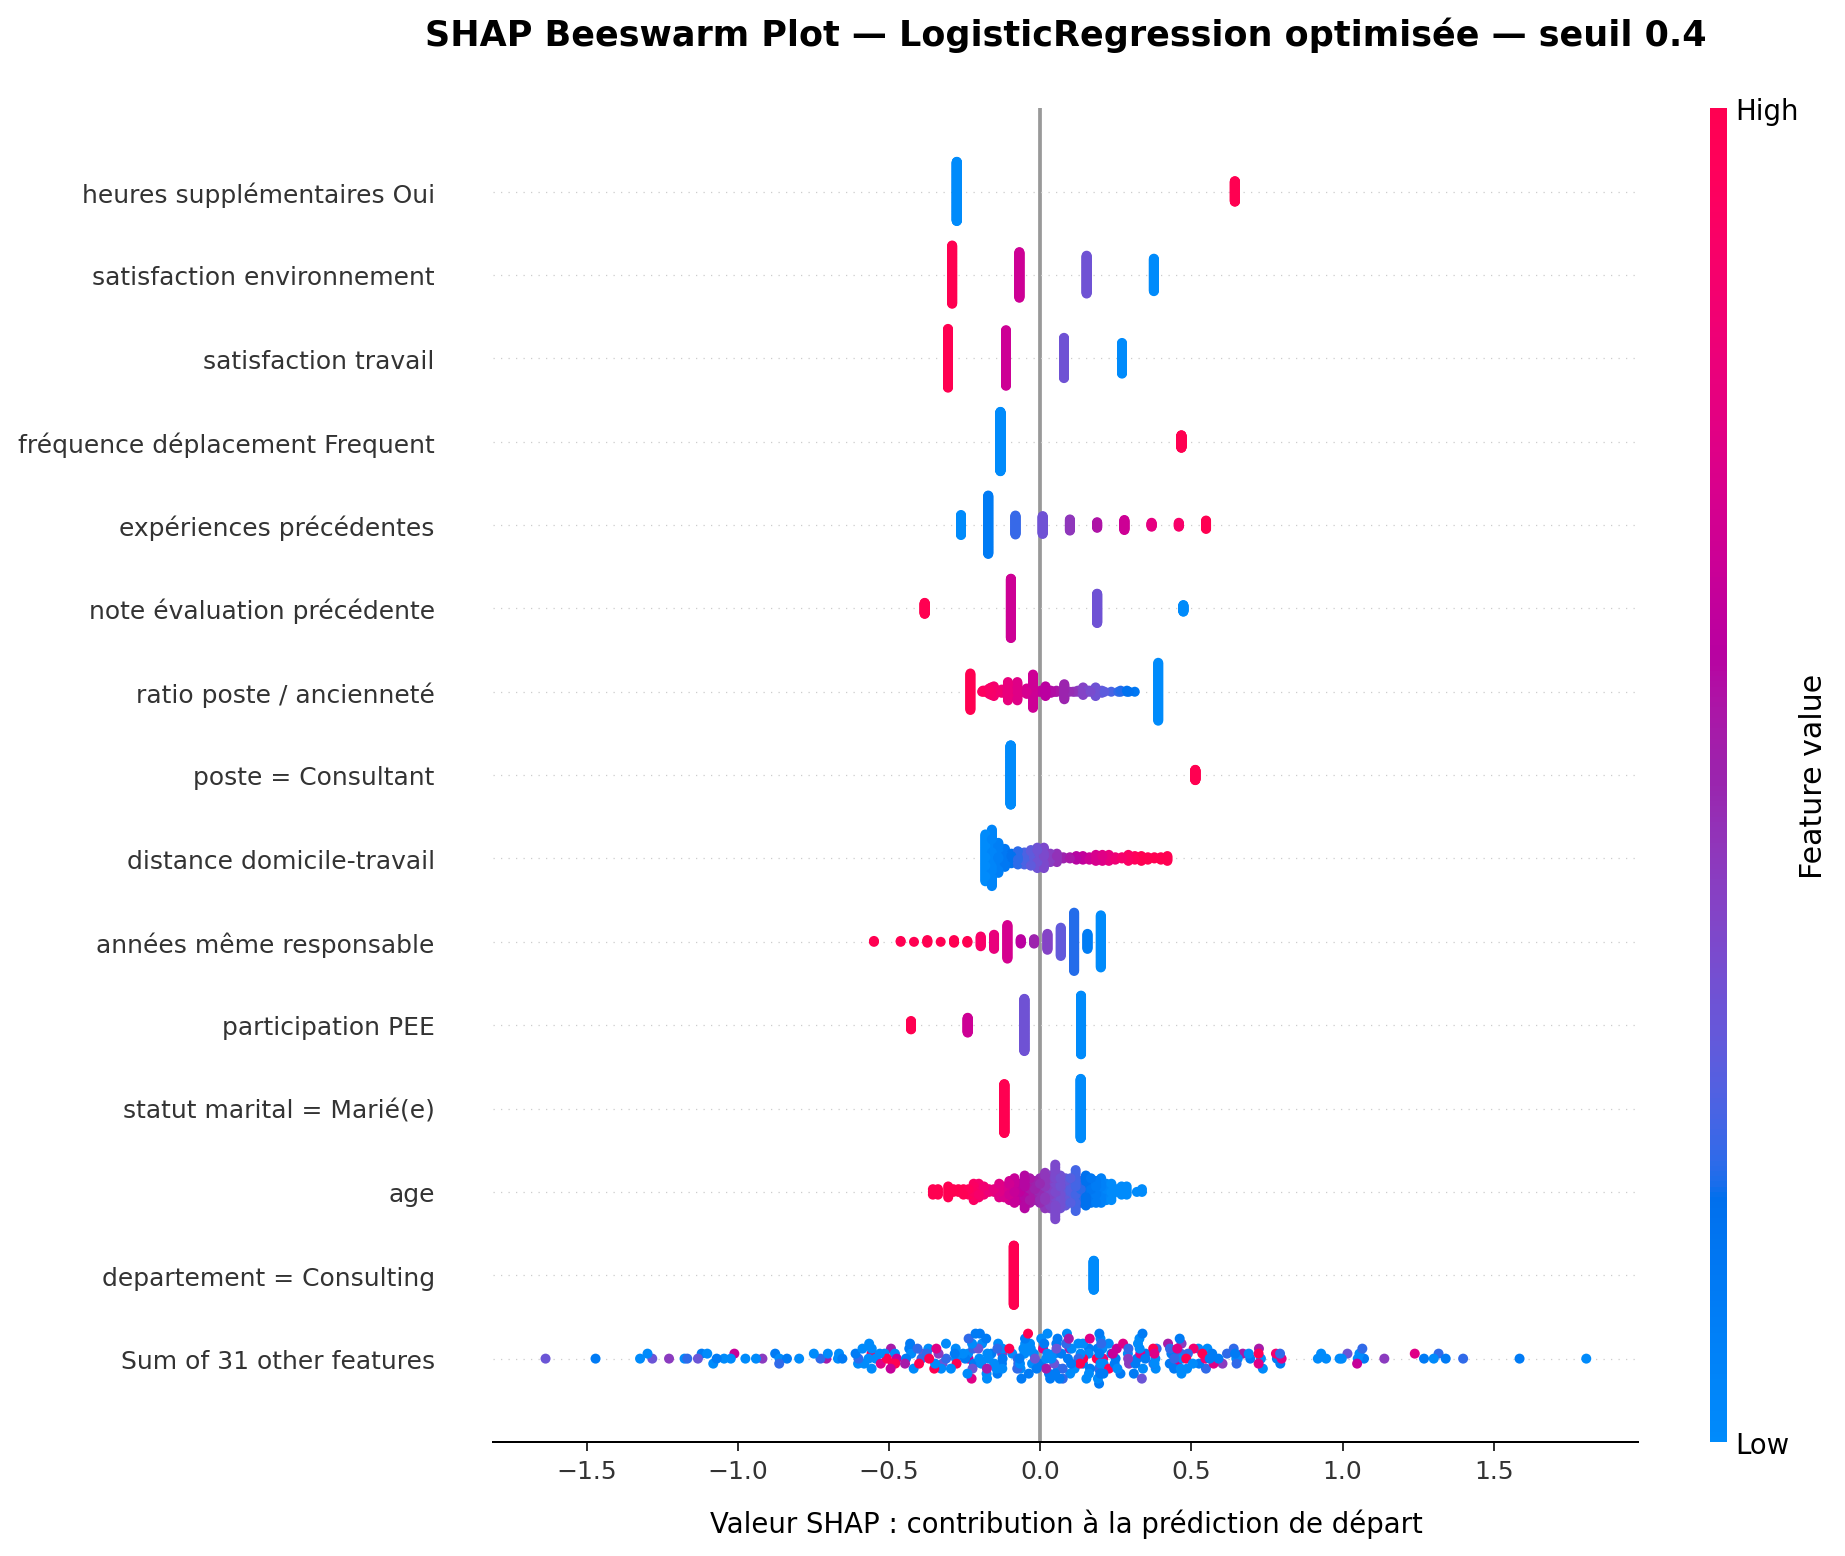

In [63]:
import textwrap
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
import shap


max_display_beeswarm = 15


def nettoyer_nom_feature_shap(nom_feature, largeur_max=35):
    """
    Rend les noms de features SHAP plus lisibles.
    """

    nom = str(nom_feature)

    nom = nom.replace("numerique__", "")
    nom = nom.replace("categoriel__", "")

    remplacements = {
        "satisfaction_employee_environnement": "satisfaction environnement",
        "satisfaction_employee_nature_travail": "satisfaction travail",
        "satisfaction_employee_equipe": "satisfaction équipe",
        "satisfaction_employee_equilibre_pro_perso": "équilibre pro/perso",
        "annee_experience_totale": "expérience totale",
        "annees_dans_l_entreprise": "ancienneté entreprise",
        "annees_dans_le_poste_actuel": "ancienneté poste",
        "annees_depuis_la_derniere_promotion": "années depuis promotion",
        "annes_sous_responsable_actuel": "années même responsable",
        "augmentation_salaire_precedente_pct": "augmentation salaire %",
        "revenu_par_annee_experience": "revenu / année expérience",
        "ratio_anciennete_experience": "ratio ancienneté / expérience",
        "ratio_temps_poste_anciennete": "ratio poste / ancienneté",
        "ratio_promotion_anciennete": "ratio promotion / ancienneté",
        "nombre_experiences_precedentes": "expériences précédentes",
        "nombre_participation_pee": "participation PEE",
        "nb_formations_suivies": "formations suivies",
        "distance_domicile_travail": "distance domicile-travail",
        "note_evaluation_precedente": "note évaluation précédente",
        "note_evaluation_actuelle": "note évaluation actuelle",
        "niveau_hierarchique_poste": "niveau hiérarchique",
        "heure_supplementaires": "heures supplémentaires",
        "frequence_deplacement": "fréquence déplacement",
        "revenu_mensuel": "revenu mensuel",
    }

    for ancien, nouveau in remplacements.items():
        nom = nom.replace(ancien, nouveau)

    variables_categorielles_connues = [
        "genre",
        "statut_marital",
        "departement",
        "poste",
        "heure_supplementaires",
        "domaine_etude",
        "frequence_deplacement"
    ]

    for variable in variables_categorielles_connues:
        prefixe = f"{variable}_"
        if nom.startswith(prefixe):
            modalite = nom.replace(prefixe, "")
            nom = f"{variable} = {modalite}"
            break

    nom = nom.replace("_", " ")

    nom = "\n".join(
        textwrap.wrap(
            nom,
            width=largeur_max,
            break_long_words=False
        )
    )

    return nom


# ============================================================
# Récupération robuste des noms de features
# ============================================================

if hasattr(shap_values_classe_1, "feature_names") and shap_values_classe_1.feature_names is not None:
    noms_features_source = list(shap_values_classe_1.feature_names)
else:
    noms_features_source = list(X_test_shap.columns)

noms_features_courts = [
    nettoyer_nom_feature_shap(feature)
    for feature in noms_features_source
]


# ============================================================
# Recréation d'un objet SHAP avec noms lisibles
# ============================================================

shap_values_beeswarm_lisible = shap.Explanation(
    values=shap_values_classe_1.values,
    base_values=shap_values_classe_1.base_values,
    data=shap_values_classe_1.data,
    feature_names=noms_features_courts
)


# ============================================================
# Beeswarm plus lisible
# ============================================================

hauteur_figure = max(8, max_display_beeswarm * 0.65)

try:
    shap.plots.beeswarm(
        shap_values_beeswarm_lisible,
        max_display=max_display_beeswarm,
        show=False,
        plot_size=(15, hauteur_figure)
    )
except TypeError:
    plt.figure(figsize=(15, hauteur_figure))
    shap.plots.beeswarm(
        shap_values_beeswarm_lisible,
        max_display=max_display_beeswarm,
        show=False
    )

fig = plt.gcf()
ax = plt.gca()

ax.set_title(
    f"SHAP Beeswarm Plot — {nom_modele_explicabilite}",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Valeur SHAP : contribution à la prédiction de départ",
    fontsize=11,
    labelpad=10
)

ax.tick_params(axis="y", labelsize=10)
ax.tick_params(axis="x", labelsize=10)

plt.subplots_adjust(
    left=0.45,
    right=0.98,
    top=0.88,
    bottom=0.12
)

chemin_beeswarm_lisible = Path("shap_beeswarm_global_lisible.png")

fig.savefig(
    chemin_beeswarm_lisible,
    dpi=180,
    bbox_inches="tight"
)

plt.close(fig)

display(Image(filename=str(chemin_beeswarm_lisible)))

In [64]:
df_shap_importance_features = pd.DataFrame({
    "feature_apres_preprocessing": X_test_shap.columns,
    "importance_moyenne_abs_shap": np.abs(shap_values_classe_1.values).mean(axis=0)
})

df_shap_importance_features = (
    df_shap_importance_features
    .sort_values(by="importance_moyenne_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(df_shap_importance_features.head(20).round(4))

,feature_apres_preprocessing,importance_moyenne_abs_shap
0,categoriel__heure_supplementaires_Oui,0.3711
1,numerique__satisfaction_employee_environnement,0.2189
2,numerique__satisfaction_employee_nature_travail,0.1926
3,categoriel__frequence_deplacement_Frequent,0.1910
4,numerique__nombre_experiences_precedentes,0.1901
5,numerique__note_evaluation_precedente,0.1765
6,numerique__ratio_temps_poste_anciennete,0.1704
7,categoriel__poste_Consultant,0.1599
8,numerique__distance_domicile_travail,0.1392
9,numerique__annes_sous_responsable_actuel,0.1390


Cellule 10 — Regrouper SHAP par variable d’origine

Comme SHAP travaille après one-hot encoding, une variable catégorielle comme poste peut produire plusieurs colonnes :

categoriel__poste_Manager
categoriel__poste_Tech Lead
categoriel__poste_Consultant
...

On les regroupe donc par variable d’origine pour comparer avec la Permutation Importance.

In [65]:
def retrouver_variable_originale_depuis_feature(feature, colonnes_numeriques, colonnes_categorielles):
    """
    Retrouve la variable d'origine à partir du nom après preprocessing.
    """
    
    if feature.startswith("numerique__"):
        return feature.replace("numerique__", "")
    
    if feature.startswith("categoriel__"):
        nom_sans_prefixe = feature.replace("categoriel__", "")
        
        for col in sorted(colonnes_categorielles, key=len, reverse=True):
            prefixe = f"{col}_"
            if nom_sans_prefixe.startswith(prefixe):
                return col
    
    return feature


df_shap_importance_features["variable_originale"] = (
    df_shap_importance_features["feature_apres_preprocessing"]
    .apply(
        lambda x: retrouver_variable_originale_depuis_feature(
            x,
            colonnes_numeriques,
            colonnes_categorielles
        )
    )
)

df_shap_importance_variables = (
    df_shap_importance_features
    .groupby("variable_originale", as_index=False)
    .agg(
        importance_shap_globale=("importance_moyenne_abs_shap", "sum"),
        nombre_features_encodees=("feature_apres_preprocessing", "count")
    )
    .sort_values(by="importance_shap_globale", ascending=False)
    .reset_index(drop=True)
)

display(df_shap_importance_variables.head(20).round(4))

,variable_originale,importance_shap_globale,nombre_features_encodees
0,poste,0.4795,8
1,heure_supplementaires,0.3711,1
2,frequence_deplacement,0.2494,2
3,statut_marital,0.2379,2
4,satisfaction_employee_environnement,0.2189,1
5,satisfaction_employee_nature_travail,0.1926,1
6,nombre_experiences_precedentes,0.1901,1
7,note_evaluation_precedente,0.1765,1
8,ratio_temps_poste_anciennete,0.1704,1
9,distance_domicile_travail,0.1392,1


Comparaison Permutation Importance vs SHAP

In [66]:
df_comparaison_importances = df_permutation_importance.merge(
    df_shap_importance_variables,
    on="variable_originale",
    how="outer"
)

df_comparaison_importances = df_comparaison_importances.fillna(0)

# Normalisation pour comparer les classements
df_comparaison_importances["permutation_norm"] = (
    df_comparaison_importances["importance_moyenne_permutation"]
    / df_comparaison_importances["importance_moyenne_permutation"].abs().sum()
)

df_comparaison_importances["shap_norm"] = (
    df_comparaison_importances["importance_shap_globale"]
    / df_comparaison_importances["importance_shap_globale"].abs().sum()
)

df_comparaison_importances["rang_permutation"] = (
    df_comparaison_importances["importance_moyenne_permutation"]
    .rank(ascending=False, method="dense")
)

df_comparaison_importances["rang_shap"] = (
    df_comparaison_importances["importance_shap_globale"]
    .rank(ascending=False, method="dense")
)

df_comparaison_importances["ecart_rang"] = (
    df_comparaison_importances["rang_permutation"]
    - df_comparaison_importances["rang_shap"]
).abs()

df_comparaison_importances = (
    df_comparaison_importances
    .sort_values(by="shap_norm", ascending=False)
    .reset_index(drop=True)
)

display(df_comparaison_importances.round(4).head(25))

,variable_originale,importance_moyenne_permutation,importance_std_permutation,importance_shap_globale,nombre_features_encodees,permutation_norm,shap_norm,rang_permutation,rang_shap,ecart_rang
0,poste,0.0245,0.0259,0.4795,8.0,0.0502,0.1214,9.0,1.0,8.0
1,heure_supplementaires,0.0909,0.0168,0.3711,1.0,0.1865,0.0939,1.0,2.0,1.0
2,frequence_deplacement,0.0041,0.0131,0.2494,2.0,0.0084,0.0631,18.0,3.0,15.0
3,statut_marital,0.0326,0.0186,0.2379,2.0,0.0668,0.0602,5.0,4.0,1.0
4,satisfaction_employee_environnement,0.0327,0.0283,0.2189,1.0,0.0672,0.0554,4.0,5.0,1.0
5,satisfaction_employee_nature_travail,0.0269,0.0225,0.1926,1.0,0.0553,0.0488,8.0,6.0,2.0
6,nombre_experiences_precedentes,0.0374,0.0170,0.1901,1.0,0.0766,0.0481,3.0,7.0,4.0
7,note_evaluation_precedente,0.0031,0.0154,0.1765,1.0,0.0063,0.0447,19.0,8.0,11.0
8,ratio_temps_poste_anciennete,0.0474,0.0252,0.1704,1.0,0.0972,0.0431,2.0,9.0,7.0
9,distance_domicile_travail,0.0083,0.0135,0.1392,1.0,0.0171,0.0352,13.0,10.0,3.0


Graphique de comparaison des importances globales

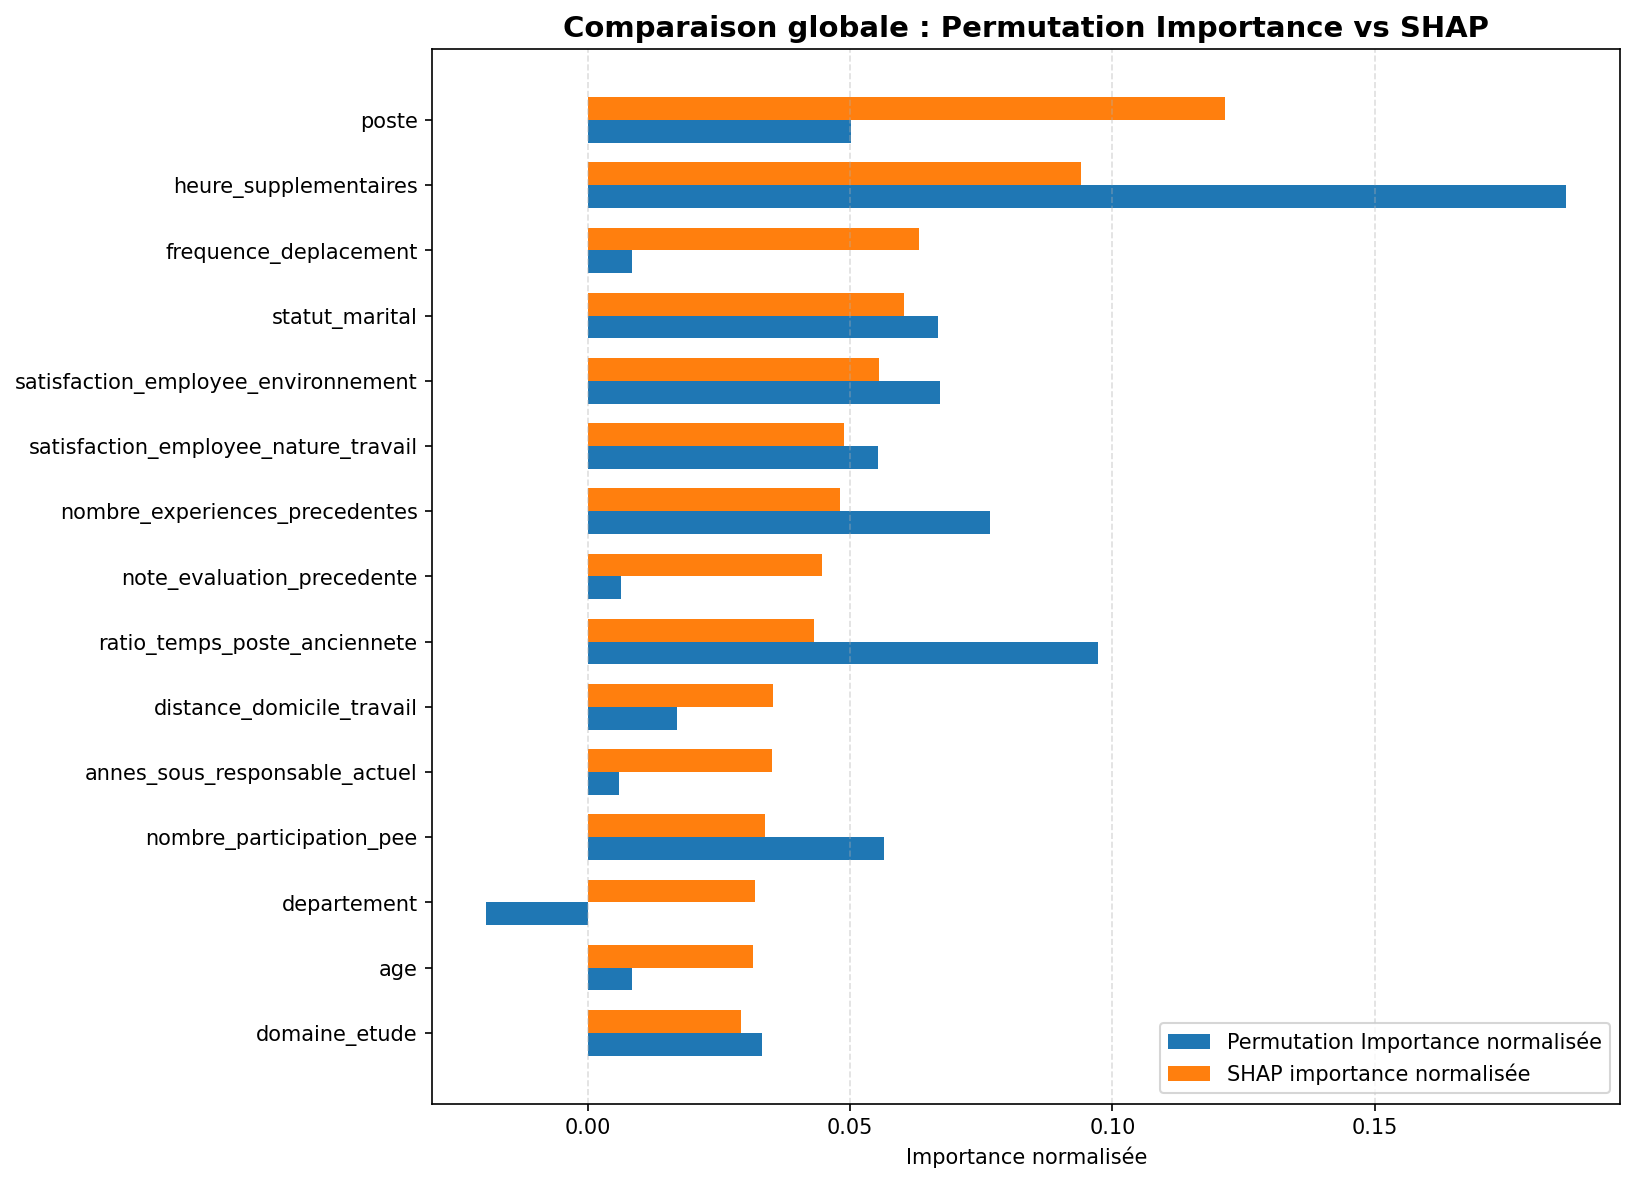

In [67]:
top_n = 15

variables_top = (
    df_comparaison_importances
    .head(top_n)["variable_originale"]
    .tolist()
)

df_plot_compare = (
    df_comparaison_importances
    .loc[df_comparaison_importances["variable_originale"].isin(variables_top)]
    .copy()
    .sort_values(by="shap_norm", ascending=True)
)

y_pos = np.arange(len(df_plot_compare))
hauteur_barre = 0.35

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    y_pos - hauteur_barre / 2,
    df_plot_compare["permutation_norm"],
    height=hauteur_barre,
    label="Permutation Importance normalisée"
)

ax.barh(
    y_pos + hauteur_barre / 2,
    df_plot_compare["shap_norm"],
    height=hauteur_barre,
    label="SHAP importance normalisée"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(df_plot_compare["variable_originale"])

ax.set_xlabel("Importance normalisée")
ax.set_title(
    "Comparaison globale : Permutation Importance vs SHAP",
    fontsize=14,
    fontweight="bold"
)

ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

chemin_comparaison = Path("comparaison_permutation_shap.png")
fig.savefig(chemin_comparaison, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(chemin_comparaison)))

### Analyse des convergences et divergences

La Permutation Importance et SHAP ne mesurent pas exactement la même chose.

La **Permutation Importance** mesure la baisse de performance du modèle lorsqu'une variable est mélangée. Elle répond donc à la question :

> Si cette variable n'était plus exploitable, à quel point le score du modèle se dégraderait-il ?

SHAP mesure plutôt la contribution moyenne des variables aux prédictions individuelles. Elle répond à la question :

> Quelles variables contribuent le plus aux prédictions du modèle, observation par observation ?

Les points de convergence sont les variables qui apparaissent importantes dans les deux méthodes.  
Elles peuvent être considérées comme des variables robustement importantes pour le modèle.

Les points de divergence peuvent venir de plusieurs raisons :

- variables corrélées entre elles ;
- variables catégorielles éclatées en plusieurs colonnes one-hot ;
- variable utile pour certaines observations seulement ;
- variable qui influence fortement la probabilité mais peu la métrique F5 globale ;
- instabilité liée au petit nombre d'observations positives.

Ces méthodes ne prouvent pas une causalité. Elles expliquent le comportement du modèle prédictif.

Feature principale : categoriel__heure_supplementaires_Oui
Feature utilisée pour colorer : numerique__satisfaction_employee_environnement


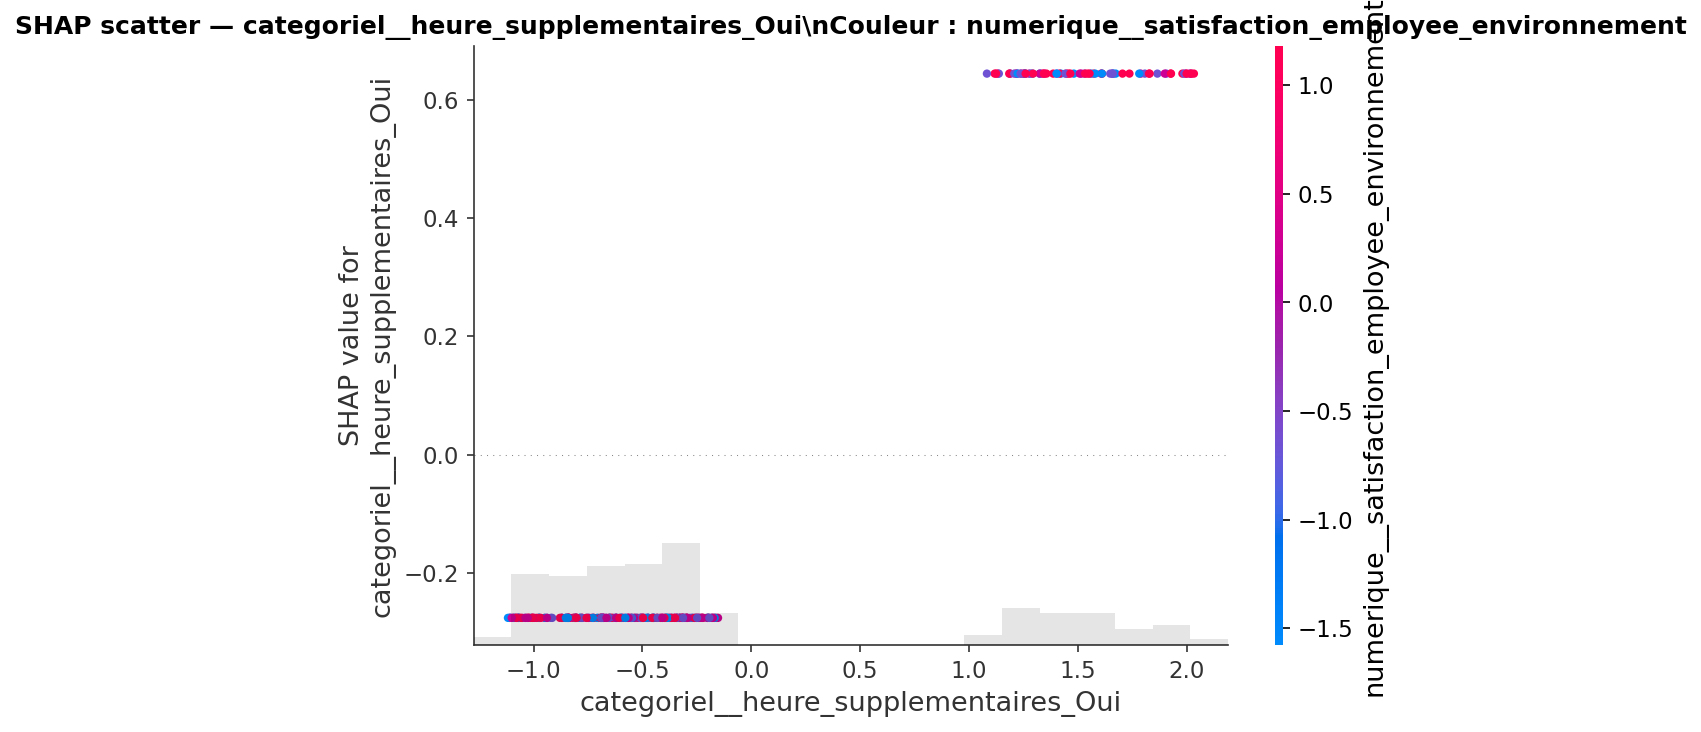

In [68]:
# On prend la feature SHAP la plus importante
feature_principale = df_shap_importance_features.loc[0, "feature_apres_preprocessing"]

# On prend une deuxième feature importante pour colorer les points
feature_couleur = df_shap_importance_features.loc[1, "feature_apres_preprocessing"]

print("Feature principale :", feature_principale)
print("Feature utilisée pour colorer :", feature_couleur)

shap.plots.scatter(
    shap_values_classe_1[:, feature_principale],
    color=shap_values_classe_1[:, feature_couleur],
    show=False
)

plt.title(
    f"SHAP scatter — {feature_principale}\\nCouleur : {feature_couleur}",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()

chemin_scatter = Path("shap_scatter_color.png")
plt.savefig(chemin_scatter, dpi=150, bbox_inches="tight")
plt.close()

display(Image(filename=str(chemin_scatter)))

### Interprétation du SHAP scatter

Sur le graphique SHAP scatter :

- l'axe horizontal représente la valeur de la feature ;
- l'axe vertical représente la valeur SHAP associée ;
- une valeur SHAP positive pousse la prédiction vers la classe `1`, c'est-à-dire le départ ;
- une valeur SHAP négative pousse la prédiction vers la classe `0`, c'est-à-dire le maintien dans l'entreprise ;
- la couleur permet d'observer si une autre variable modifie l'effet de la feature principale.

Si les points montent lorsque la valeur de la feature augmente, alors cette feature augmente le risque prédit de départ.  
Si les points descendent, elle diminue le risque prédit.

In [69]:
y_score_explicabilite = modele_explicabilite.predict_proba(X_test_cache)[:, 1]

y_pred_explicabilite = (
    y_score_explicabilite >= seuil_explicabilite
).astype(int)

df_exemples_locaux = pd.DataFrame({
    "position": range(len(y_test_cache)),
    "index_original": X_test_cache.index,
    "y_true": y_test_cache.values,
    "y_pred": y_pred_explicabilite,
    "probabilite_depart": y_score_explicabilite
})

def type_cas(row):
    if row["y_true"] == 0 and row["y_pred"] == 0:
        return "TN - stable bien prédit"
    if row["y_true"] == 0 and row["y_pred"] == 1:
        return "FP - fausse alerte"
    if row["y_true"] == 1 and row["y_pred"] == 0:
        return "FN - départ manqué"
    if row["y_true"] == 1 and row["y_pred"] == 1:
        return "TP - départ détecté"

df_exemples_locaux["type_cas"] = df_exemples_locaux.apply(type_cas, axis=1)

display(
    df_exemples_locaux
    .sort_values(by=["type_cas", "probabilite_depart"])
    .groupby("type_cas")
    .head(3)
)

,position,index_original,y_true,y_pred,probabilite_depart,type_cas
240,240,1111,1,0,0.073258,FN - départ manqué
82,82,126,1,0,0.090119,FN - départ manqué
29,29,45,1,0,0.206358,FN - départ manqué
280,280,1147,0,1,0.403825,FP - fausse alerte
50,50,1047,0,1,0.405333,FP - fausse alerte
284,284,41,0,1,0.407469,FP - fausse alerte
76,76,1054,0,0,0.058727,TN - stable bien prédit
107,107,257,0,0,0.058900,TN - stable bien prédit
100,100,770,0,0,0.059172,TN - stable bien prédit
97,97,217,1,1,0.411747,TP - départ détecté


In [70]:
cas_selectionnes = []

for cas in [
    "TN - stable bien prédit",
    "FP - fausse alerte",
    "FN - départ manqué",
    "TP - départ détecté"
]:
    df_cas = df_exemples_locaux.query("type_cas == @cas")
    
    if len(df_cas) > 0:
        # On prend l'exemple le plus représentatif selon la probabilité
        if cas.startswith("TN"):
            exemple = df_cas.sort_values("probabilite_depart", ascending=True).iloc[0]
        elif cas.startswith("TP"):
            exemple = df_cas.sort_values("probabilite_depart", ascending=False).iloc[0]
        else:
            exemple = df_cas.sort_values("probabilite_depart", ascending=False).iloc[0]
        
        cas_selectionnes.append(exemple)

df_cas_selectionnes = pd.DataFrame(cas_selectionnes)

display(df_cas_selectionnes)

,position,index_original,y_true,y_pred,probabilite_depart,type_cas
76,76,1054,0,0,0.058727,TN - stable bien prédit
223,223,301,0,1,0.878562,FP - fausse alerte
27,27,136,1,0,0.393169,FN - départ manqué
92,92,911,1,1,0.963071,TP - départ détecté


### Interprétation des Waterfall Plots

Les Waterfall Plots permettent d'expliquer une prédiction individuelle.

Chaque graphique montre comment les variables déplacent la prédiction :

- vers la classe `1`, donc vers le départ ;
- ou vers la classe `0`, donc vers le maintien dans l'entreprise.

Une contribution SHAP positive augmente le risque prédit de départ.  
Une contribution SHAP négative diminue le risque prédit de départ.

L'intérêt est de comprendre pourquoi deux employés peuvent être prédits différemment, même si le modèle global est le même.

On peut notamment comparer :

- un vrai positif : employé qui quitte et que le modèle détecte ;
- un faux positif : employé signalé à risque mais qui reste ;
- un faux négatif : employé qui quitte mais que le modèle ne détecte pas ;
- un vrai négatif : employé stable correctement identifié.

Cas : TN - stable bien prédit
Position dans le jeu de test : 76
Index original : 1054
Classe réelle : 0
Classe prédite : 0
Probabilité prédite de départ : 0.059


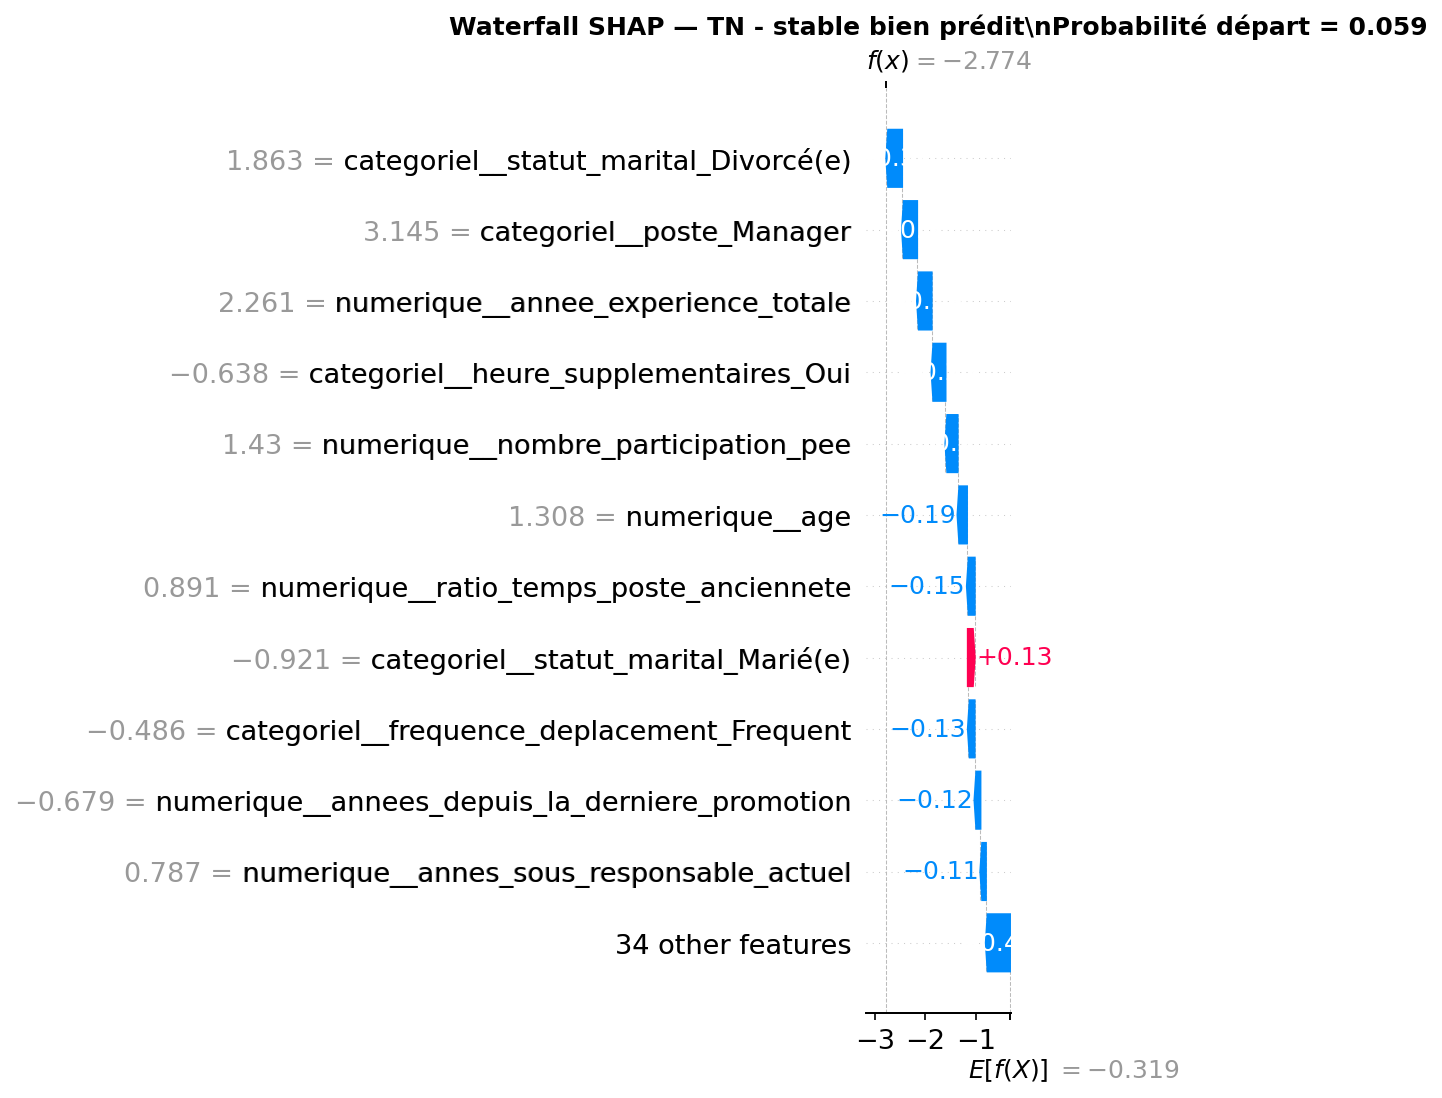

Cas : FP - fausse alerte
Position dans le jeu de test : 223
Index original : 301
Classe réelle : 0
Classe prédite : 1
Probabilité prédite de départ : 0.879


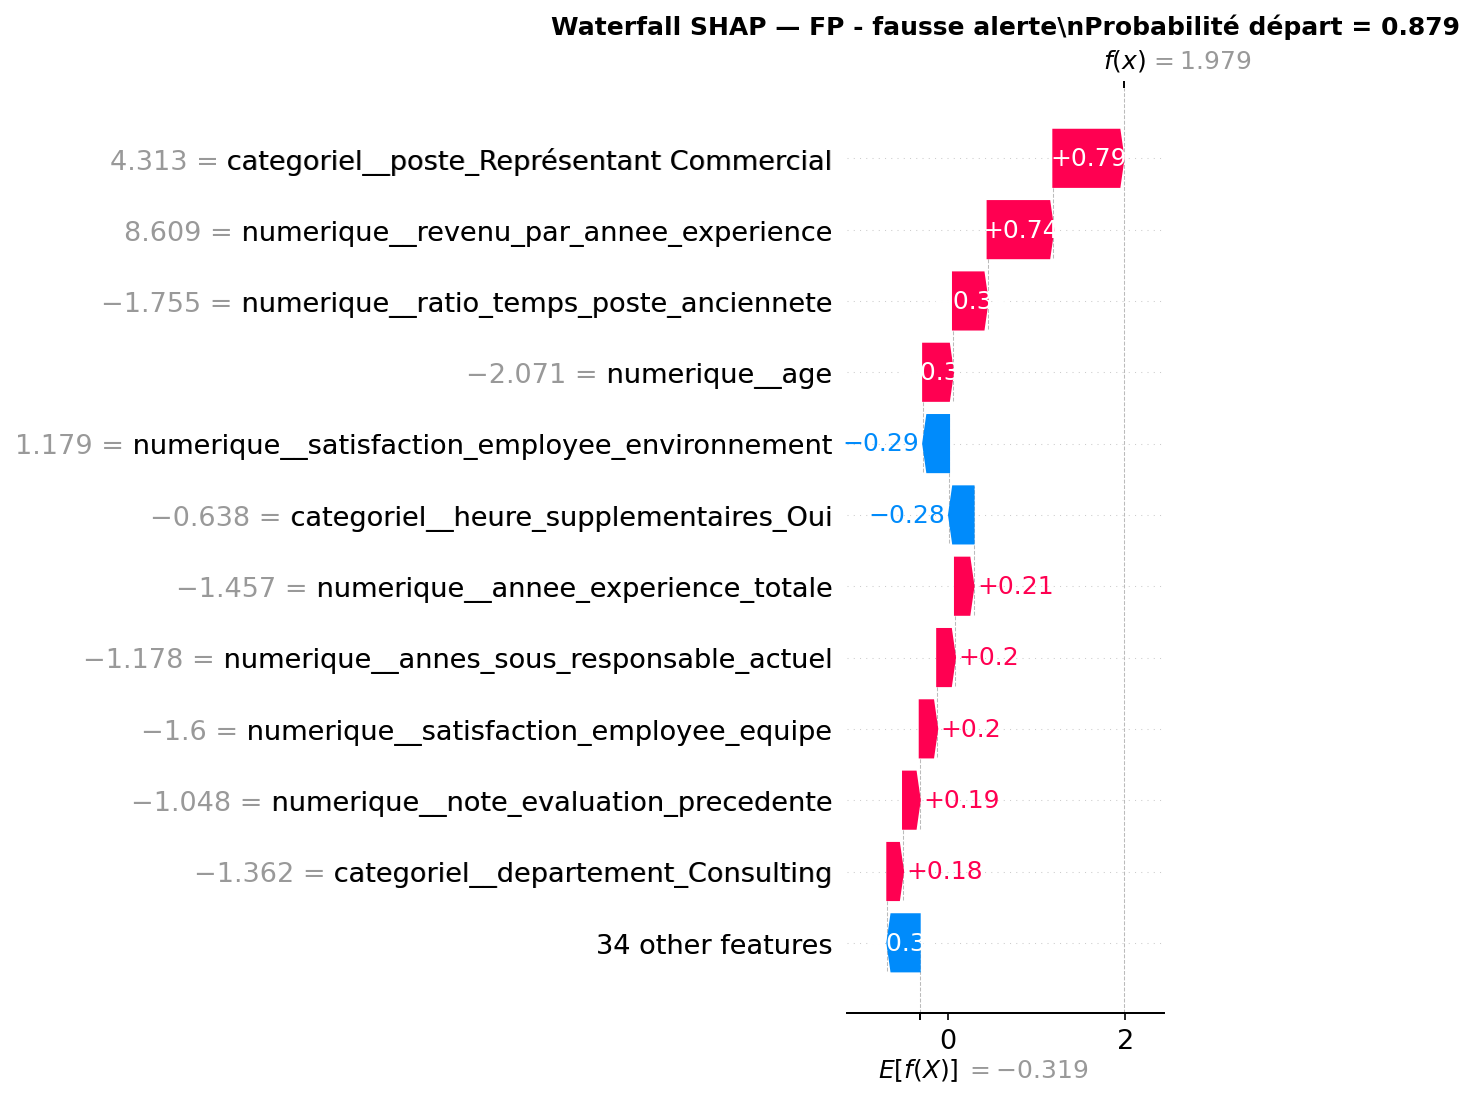

Cas : FN - départ manqué
Position dans le jeu de test : 27
Index original : 136
Classe réelle : 1
Classe prédite : 0
Probabilité prédite de départ : 0.393


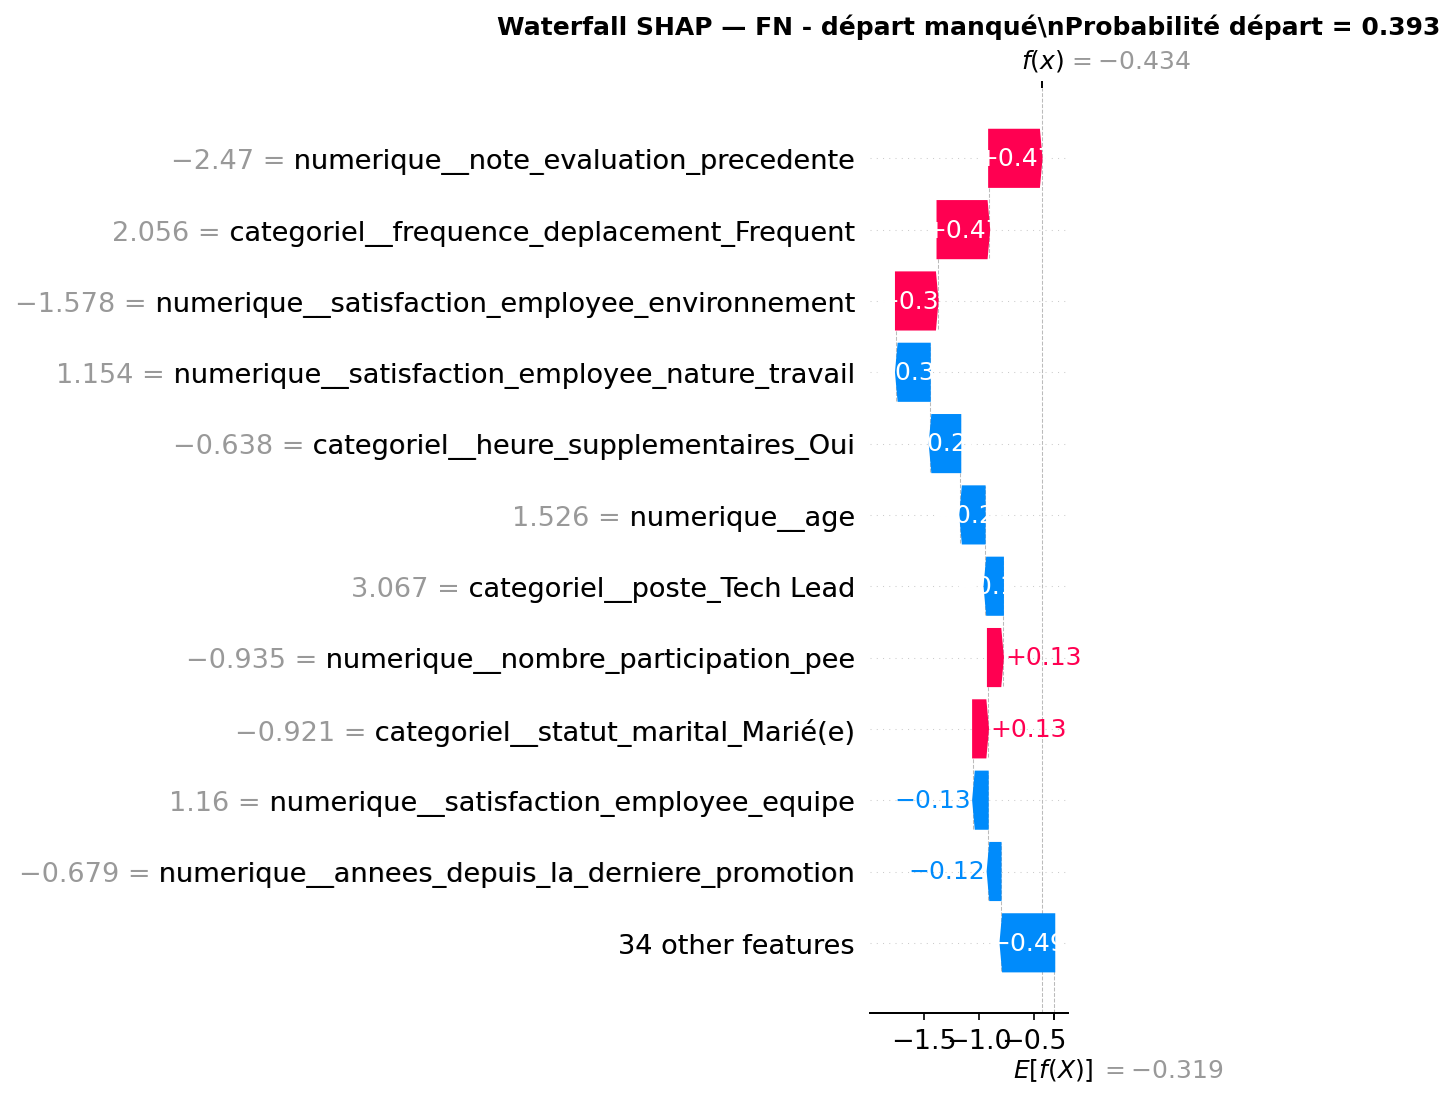

Cas : TP - départ détecté
Position dans le jeu de test : 92
Index original : 911
Classe réelle : 1
Classe prédite : 1
Probabilité prédite de départ : 0.963


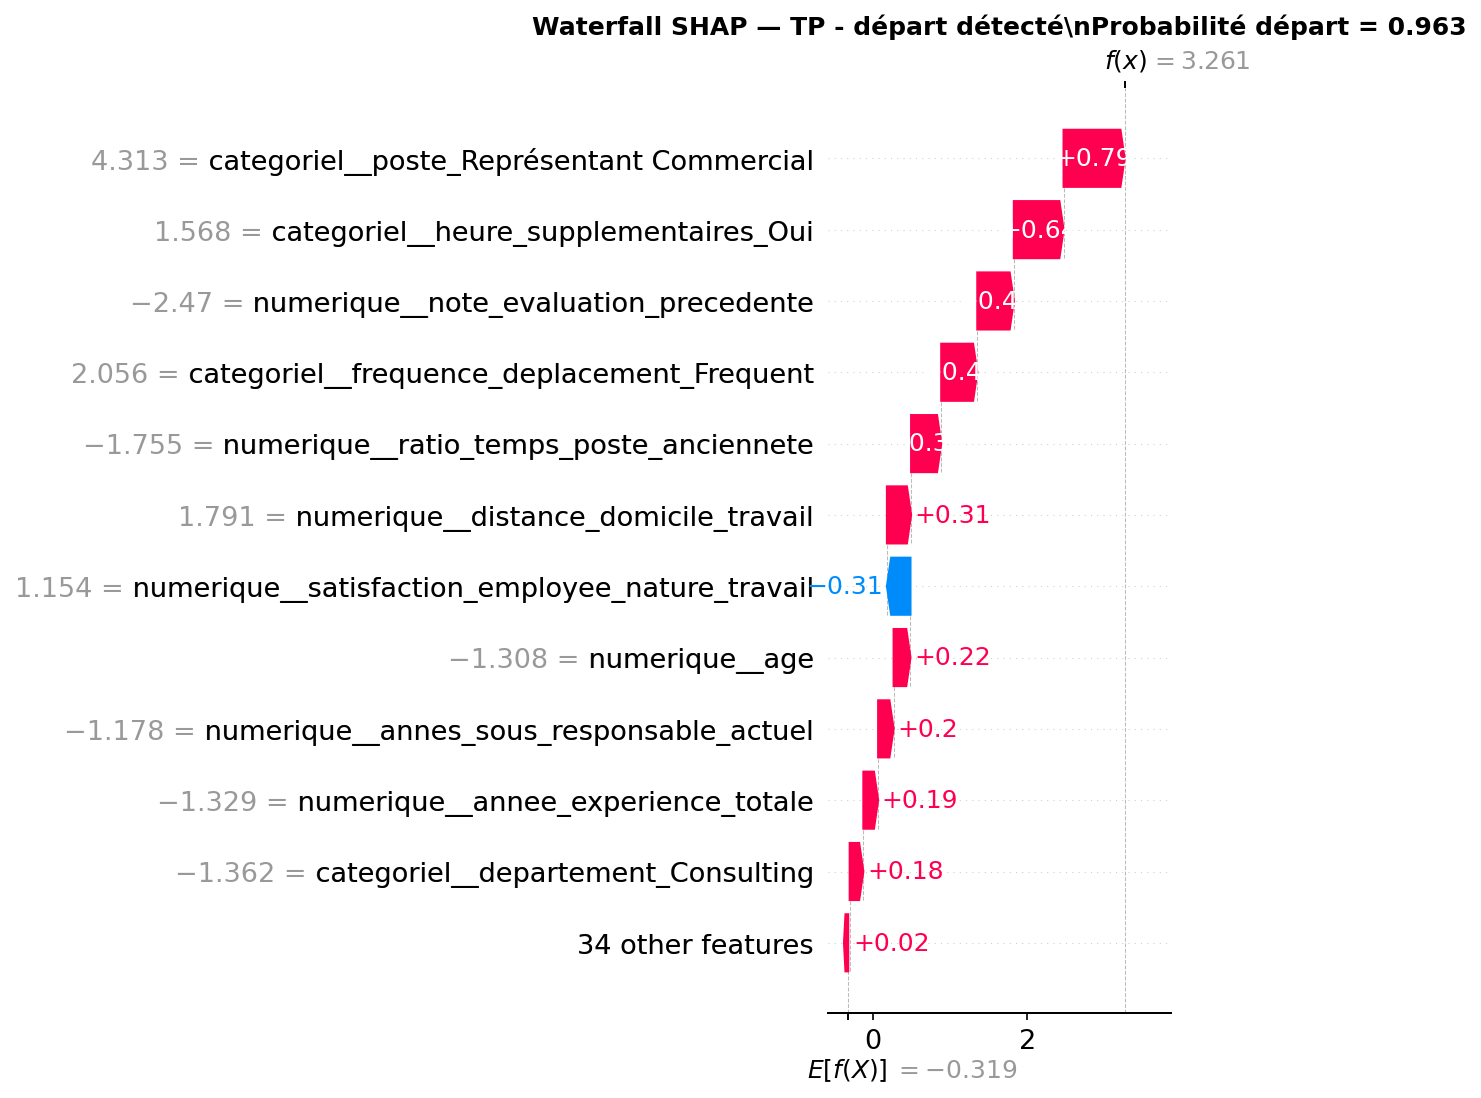

In [71]:
for _, ligne in df_cas_selectionnes.iterrows():
    position = int(ligne["position"])
    type_cas_local = ligne["type_cas"]
    proba = ligne["probabilite_depart"]
    
    print("=" * 100)
    print(f"Cas : {type_cas_local}")
    print(f"Position dans le jeu de test : {position}")
    print(f"Index original : {ligne['index_original']}")
    print(f"Classe réelle : {ligne['y_true']}")
    print(f"Classe prédite : {ligne['y_pred']}")
    print(f"Probabilité prédite de départ : {proba:.3f}")
    print("=" * 100)
    
    shap.plots.waterfall(
        shap_values_classe_1[position],
        max_display=12,
        show=False
    )
    
    plt.title(
        f"Waterfall SHAP — {type_cas_local}\\nProbabilité départ = {proba:.3f}",
        fontsize=12,
        fontweight="bold"
    )
    
    plt.tight_layout()
    
    nom_fichier = (
        "waterfall_"
        + type_cas_local
        .replace(" ", "_")
        .replace("-", "")
        .replace("é", "e")
        .replace("è", "e")
        .replace("à", "a")
        .lower()
        + ".png"
    )
    
    chemin_waterfall = Path(nom_fichier)
    
    plt.savefig(
        chemin_waterfall,
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.close()
    
    display(Image(filename=str(chemin_waterfall)))

Personne qui part réellement
Position : 4
Classe réelle : 1
Classe prédite : 1
Probabilité prédite de départ : 0.652

Personne qui reste réellement
Position : 1
Classe réelle : 0
Classe prédite : 0
Probabilité prédite de départ : 0.155


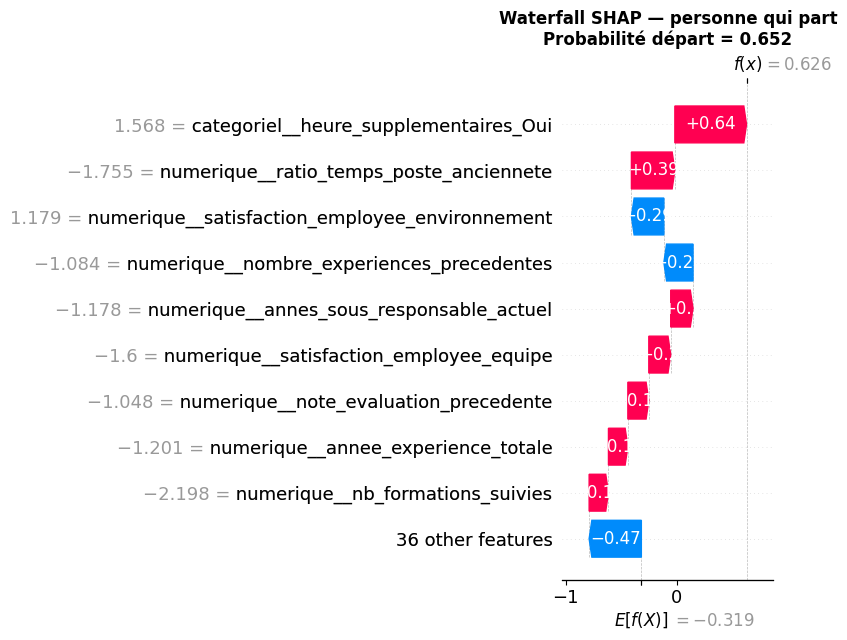

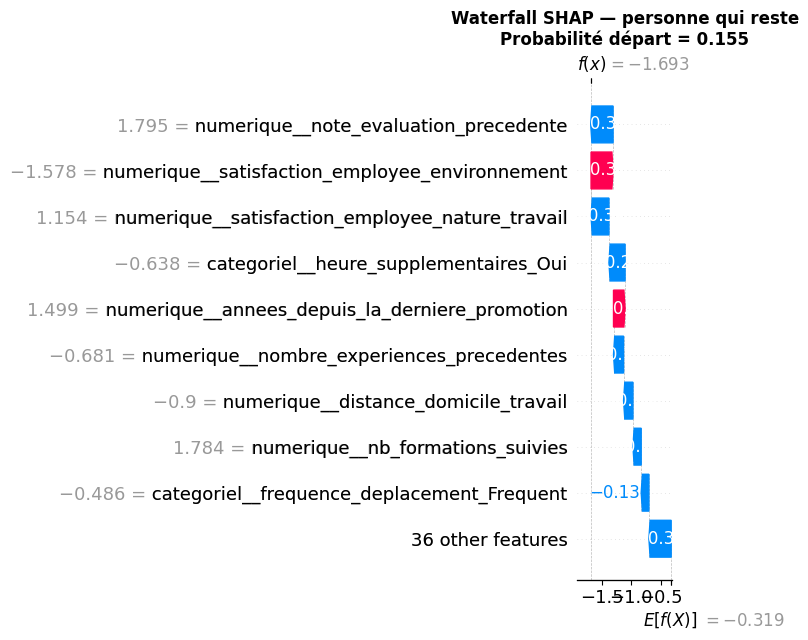

In [72]:
import numpy as np
import shap
import matplotlib.pyplot as plt


# ============================================================
# 1. Prédictions avec le seuil retenu
# ============================================================

y_score = modele_explicabilite.predict_proba(X_test_cache)[:, 1]

y_pred = (
    y_score >= seuil_explicabilite
).astype(int)

y_true = y_test_cache.values


# ============================================================
# 2. Sélection minimale de 2 individus
#    - 1 personne qui part réellement
#    - 1 personne qui reste réellement
# ============================================================

# On privilégie un vrai positif : part réellement et prédit comme partant
positions_part = np.where((y_true == 1) & (y_pred == 1))[0]

# Si aucun vrai positif, on prend simplement une personne qui part réellement
if len(positions_part) == 0:
    positions_part = np.where(y_true == 1)[0]

position_part = positions_part[0]


# On privilégie un vrai négatif : reste réellement et prédit comme restant
positions_reste = np.where((y_true == 0) & (y_pred == 0))[0]

# Si aucun vrai négatif, on prend simplement une personne qui reste réellement
if len(positions_reste) == 0:
    positions_reste = np.where(y_true == 0)[0]

position_reste = positions_reste[0]


# ============================================================
# 3. Résumé des deux individus choisis
# ============================================================

print("Personne qui part réellement")
print("Position :", position_part)
print("Classe réelle :", y_true[position_part])
print("Classe prédite :", y_pred[position_part])
print("Probabilité prédite de départ :", round(y_score[position_part], 3))

print("\nPersonne qui reste réellement")
print("Position :", position_reste)
print("Classe réelle :", y_true[position_reste])
print("Classe prédite :", y_pred[position_reste])
print("Probabilité prédite de départ :", round(y_score[position_reste], 3))


# ============================================================
# 4. Waterfall SHAP — personne qui part
# ============================================================

shap.plots.waterfall(
    shap_values_classe_1[position_part],
    max_display=10,
    show=False
)

plt.title(
    f"Waterfall SHAP — personne qui part\n"
    f"Probabilité départ = {y_score[position_part]:.3f}",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. Waterfall SHAP — personne qui reste
# ============================================================

shap.plots.waterfall(
    shap_values_classe_1[position_reste],
    max_display=10,
    show=False
)

plt.title(
    f"Waterfall SHAP — personne qui reste\n"
    f"Probabilité départ = {y_score[position_reste]:.3f}",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Nous avons commencé par une analyse globale des variables avec deux méthodes complémentaires : la Permutation Importance et SHAP.

La Permutation Importance évalue l'impact d'une variable sur la performance du modèle, tandis que SHAP mesure la contribution moyenne des variables aux prédictions individuelles.

Les variables qui apparaissent importantes dans les deux méthodes peuvent être considérées comme des signaux robustes du modèle. Les divergences s'expliquent notamment par la corrélation entre variables, l'encodage one-hot des variables catégorielles et le fait que certaines variables influencent fortement certaines observations sans nécessairement dégrader fortement la performance globale lorsqu'elles sont permutées.

L'analyse locale avec les Waterfall Plots permet ensuite d'expliquer des prédictions individuelles issues des deux classes, en identifiant les variables qui poussent la prédiction vers le départ ou vers le maintien dans l'entreprise.